In [2]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
import os
import numpy as np

DATA_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences"

print("Checking dataset folder...\n")

required_files = [
    "train.npz",
    "val.npz",
    "test.npz",
    "scaler_mean.npy",
    "scaler_scale.npy",
    "metadata.json"
]

for file in required_files:
    path = os.path.join(DATA_DIR, file)
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {file:<20} {size_mb:.2f} MB")
    else:
        print(f"✗ MISSING: {file}")

print("\nLoading dataset shapes...\n")

train = np.load(os.path.join(DATA_DIR, "train.npz"))
val = np.load(os.path.join(DATA_DIR, "val.npz"))
test = np.load(os.path.join(DATA_DIR, "test.npz"))

print("TRAIN")
print("X:", train["X"].shape)
print("y:", train["y"].shape)

print("\nVALIDATION")
print("X:", val["X"].shape)
print("y:", val["y"].shape)

print("\nTEST")
print("X:", test["X"].shape)
print("y:", test["y"].shape)

Checking dataset folder...

✓ train.npz            258.03 MB
✓ val.npz              64.51 MB
✓ test.npz             64.51 MB
✓ scaler_mean.npy      0.01 MB
✓ scaler_scale.npy     0.01 MB
✓ metadata.json        0.00 MB

Loading dataset shapes...

TRAIN
X: (3000, 30, 1503)
y: (3000,)

VALIDATION
X: (750, 30, 1503)
y: (750,)

TEST
X: (750, 30, 1503)
y: (750,)


In [4]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

class BehaviourGRU(nn.Module):
    def __init__(self, input_size=1503, hidden_size=128, num_layers=2, num_classes=3):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        out, _ = self.gru(x)

        # Last time step
        out = out[:, -1, :]

        return self.classifier(out)


model = BehaviourGRU().to(device)

print(model)


Device: cuda
BehaviourGRU(
  (gru): GRU(1503, 128, num_layers=2, batch_first=True, dropout=0.3)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [5]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

DATA_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences"

# Load dataset
train = np.load(f"{DATA_DIR}/train.npz")
val   = np.load(f"{DATA_DIR}/val.npz")
test  = np.load(f"{DATA_DIR}/test.npz")

X_train = train["X"]
y_train = train["y"]

X_val = val["X"]
y_val = val["y"]

X_test = test["X"]
y_test = test["y"]

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

# Convert to PyTorch
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

# DataLoaders
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=64,
    shuffle=False
)

# Class weights
class_counts = torch.bincount(y_train)
class_weights = len(y_train) / (3 * class_counts.float())
class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Class counts:", class_counts.tolist())
print("Class weights:", class_weights.tolist())
print("TRAINING SETUP READY")

Train: (3000, 30, 1503) (3000,)
Val:   (750, 30, 1503) (750,)
Test:  (750, 30, 1503) (750,)
Class counts: [1000, 1000, 1000]
Class weights: [1.0, 1.0, 1.0]
TRAINING SETUP READY


In [6]:
import copy

EPOCHS = 30
best_val_loss = float("inf")
best_state = None

train_history = []
val_history = []

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        outputs = model(xb)
        loss = criterion(outputs, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item() * xb.size(0)
        train_correct += (outputs.argmax(1) == yb).sum().item()
        train_total += yb.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            outputs = model(xb)
            loss = criterion(outputs, yb)

            val_loss += loss.item() * xb.size(0)
            val_correct += (outputs.argmax(1) == yb).sum().item()
            val_total += yb.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    train_history.append((train_loss, train_acc))
    val_history.append((val_loss, val_acc))

    # Save BEST validation model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "model_state_dict": best_state,
                "input_size": 1503,
                "hidden_size": 128,
                "num_layers": 2,
                "num_classes": 3,
                "classes": ["Engaged", "Distracted", "Frustrated"]
            },
            "/content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt"
        )

        best_marker = "  <-- BEST"

    else:
        best_marker = ""

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
        f"{best_marker}"
    )

# Restore best model
model.load_state_dict(best_state)

print("\nTRAINING COMPLETED")
print("Best validation loss:", best_val_loss)
print("Best model saved to Google Drive.")

Epoch 01/30 | Train Loss: 0.9632 | Train Acc: 0.5437 | Val Loss: 0.9776 | Val Acc: 0.5067  <-- BEST
Epoch 02/30 | Train Loss: 0.8497 | Train Acc: 0.6170 | Val Loss: 0.9475 | Val Acc: 0.5293  <-- BEST
Epoch 03/30 | Train Loss: 0.7906 | Train Acc: 0.6510 | Val Loss: 1.0506 | Val Acc: 0.4973
Epoch 04/30 | Train Loss: 0.7527 | Train Acc: 0.6743 | Val Loss: 0.9861 | Val Acc: 0.5187
Epoch 05/30 | Train Loss: 0.7252 | Train Acc: 0.6963 | Val Loss: 0.9389 | Val Acc: 0.5440  <-- BEST
Epoch 06/30 | Train Loss: 0.6945 | Train Acc: 0.7077 | Val Loss: 1.0545 | Val Acc: 0.5360
Epoch 07/30 | Train Loss: 0.6710 | Train Acc: 0.7190 | Val Loss: 0.9091 | Val Acc: 0.5867  <-- BEST
Epoch 08/30 | Train Loss: 0.6277 | Train Acc: 0.7337 | Val Loss: 0.9907 | Val Acc: 0.5440
Epoch 09/30 | Train Loss: 0.6248 | Train Acc: 0.7480 | Val Loss: 1.0740 | Val Acc: 0.5587
Epoch 10/30 | Train Loss: 0.5970 | Train Acc: 0.7633 | Val Loss: 1.0686 | Val Acc: 0.5693
Epoch 11/30 | Train Loss: 0.5520 | Train Acc: 0.7817 | Val L

In [7]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)

        outputs = model(xb)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average="macro")

print("================================")
print("FINAL TEST RESULTS")
print("================================")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Macro F1      : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=[
            "Engaged",
            "Distracted",
            "Frustrated"
        ],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

FINAL TEST RESULTS
Test Accuracy : 0.6533
Macro F1      : 0.6487

Classification Report:
              precision    recall  f1-score   support

     Engaged     0.6070    0.4880    0.5410       250
  Distracted     0.7252    0.7600    0.7422       250
  Frustrated     0.6202    0.7120    0.6629       250

    accuracy                         0.6533       750
   macro avg     0.6508    0.6533    0.6487       750
weighted avg     0.6508    0.6533    0.6487       750


Confusion Matrix:
[[122  39  89]
 [ 40 190  20]
 [ 39  33 178]]


In [8]:
# ============================================
# LOAD & VERIFY BEST BEHAVIOUR MODEL
# ============================================

import torch

MODEL_PATH = "/content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt"

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("BEST MODEL LOADED SUCCESSFULLY")
print("Model path:", MODEL_PATH)
print("Input size:", checkpoint["input_size"])
print("Hidden size:", checkpoint["hidden_size"])
print("GRU layers:", checkpoint["num_layers"])
print("Classes:", checkpoint["classes"])

BEST MODEL LOADED SUCCESSFULLY
Model path: /content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt
Input size: 1503
Hidden size: 128
GRU layers: 2
Classes: ['Engaged', 'Distracted', 'Frustrated']


In [9]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)

        outputs = model(xb)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

accuracy = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average="macro")

print("=" * 50)
print("BEST MODEL - FINAL TEST")
print("=" * 50)

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Macro F1      : {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Engaged", "Distracted", "Frustrated"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

BEST MODEL - FINAL TEST
Test Accuracy : 0.6533
Macro F1      : 0.6487

Classification Report:
              precision    recall  f1-score   support

     Engaged     0.6070    0.4880    0.5410       250
  Distracted     0.7252    0.7600    0.7422       250
  Frustrated     0.6202    0.7120    0.6629       250

    accuracy                         0.6533       750
   macro avg     0.6508    0.6533    0.6487       750
weighted avg     0.6508    0.6533    0.6487       750


Confusion Matrix:
[[122  39  89]
 [ 40 190  20]
 [ 39  33 178]]


In [10]:
import torch
import torch.nn as nn
import copy

# ============================================
# IMPROVED BIDIRECTIONAL GRU + ATTENTION
# ============================================

class BehaviourBiGRU(nn.Module):
    def __init__(
        self,
        input_size=1503,
        hidden_size=96,
        num_layers=2,
        num_classes=3
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.35
        )

        # Attention over the 30 time steps
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 96),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(96, num_classes)
        )

    def forward(self, x):

        # [batch, 30, 1503]
        gru_out, _ = self.gru(x)

        # Attention scores
        scores = self.attention(gru_out)

        # Normalize across time
        weights = torch.softmax(scores, dim=1)

        # Weighted temporal representation
        context = torch.sum(weights * gru_out, dim=1)

        return self.classifier(context)


# Create V2 model
model_v2 = BehaviourBiGRU().to(device)

print("V2 MODEL")
print(model_v2)
print("\nDevice:", device)
print("Parameters:", sum(p.numel() for p in model_v2.parameters()))

V2 MODEL
BehaviourBiGRU(
  (gru): GRU(1503, 96, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=192, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=192, out_features=96, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=96, out_features=3, bias=True)
  )
)

Device: cuda
Parameters: 1120452


In [11]:
# ============================================================
# V2 TRAINING - BiGRU + ATTENTION
# ============================================================

import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. DEVICE
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# ------------------------------------------------------------
# 2. CONVERT NUMPY -> PYTORCH TENSORS
# ------------------------------------------------------------
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

print("Train:", X_train_t.shape, y_train_t.shape)
print("Val  :", X_val_t.shape, y_val_t.shape)

# ------------------------------------------------------------
# 3. DATA LOADERS
# ------------------------------------------------------------
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 4. MOVE MODEL TO GPU
# ------------------------------------------------------------
model_v2 = model_v2.to(device)

# ------------------------------------------------------------
# 5. LOSS + OPTIMIZER
# ------------------------------------------------------------
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_v2.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ------------------------------------------------------------
# 6. TRAINING SETTINGS
# ------------------------------------------------------------
EPOCHS = 30
PATIENCE = 7

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
patience_counter = 0

best_state = copy.deepcopy(model_v2.state_dict())

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# ------------------------------------------------------------
# 7. TRAINING LOOP
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("STARTING V2 TRAINING")
print("=" * 65)

for epoch in range(EPOCHS):

    # -------------------------
    # TRAIN
    # -------------------------
    model_v2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for xb, yb in train_loader:

        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model_v2(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model_v2.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * xb.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == yb).sum().item()
        total += yb.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # -------------------------
    # VALIDATION
    # -------------------------
    model_v2.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            outputs = model_v2(xb)

            loss = criterion(outputs, yb)

            val_running_loss += loss.item() * xb.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == yb).sum().item()
            val_total += yb.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    # Save history
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # -------------------------
    # BEST MODEL
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model_v2.state_dict())

        patience_counter = 0

        print("   --> BEST MODEL UPDATED")

    else:
        patience_counter += 1

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1} "
            f"(best epoch = {best_epoch})"
        )

        break


# ------------------------------------------------------------
# 8. RESTORE BEST MODEL
# ------------------------------------------------------------
model_v2.load_state_dict(best_state)
model_v2.eval()

print("\n" + "=" * 65)
print("V2 TRAINING COMPLETED")
print("=" * 65)

print(f"Best Epoch       : {best_epoch}")
print(f"Best Val Loss    : {best_val_loss:.4f}")
print(f"Best Val Accuracy: {best_val_acc:.4f}")

# ------------------------------------------------------------
# 9. SAVE BEST MODEL TO GOOGLE DRIVE
# ------------------------------------------------------------
MODEL_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_behaviour_v2_bigru_attention.pt"
)

checkpoint = {
    "model_state_dict": model_v2.state_dict(),
    "input_size": 1503,
    "hidden_size": 96,
    "num_layers": 2,
    "num_classes": 3,
    "classes": ["Engaged", "Distracted", "Frustrated"],
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "best_val_accuracy": best_val_acc
}

torch.save(checkpoint, MODEL_PATH)

print("\nBEST V2 MODEL SAVED")
print(MODEL_PATH)

Training device: cuda
Train: torch.Size([3000, 30, 1503]) torch.Size([3000])
Val  : torch.Size([750, 30, 1503]) torch.Size([750])

STARTING V2 TRAINING


/tmp/ipykernel_3220/1058754483.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train_t = torch.tensor(X_train, dtype=torch.float32)
/tmp/ipykernel_3220/1058754483.py:22: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train_t = torch.tensor(y_train, dtype=torch.long)
/tmp/ipykernel_3220/1058754483.py:24: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_val_t = torch.tensor(X_val, dtype=torch.float32)
/tmp/ipykernel_3220/1058754483.py:25: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clo

Epoch 01/30 | Train Loss: 0.9527 | Train Acc: 0.5503 | Val Loss: 0.9538 | Val Acc: 0.4987 | LR: 0.000500
   --> BEST MODEL UPDATED
Epoch 02/30 | Train Loss: 0.8240 | Train Acc: 0.6357 | Val Loss: 0.8976 | Val Acc: 0.5440 | LR: 0.000500
   --> BEST MODEL UPDATED
Epoch 03/30 | Train Loss: 0.7482 | Train Acc: 0.6770 | Val Loss: 0.8932 | Val Acc: 0.5600 | LR: 0.000500
   --> BEST MODEL UPDATED
Epoch 04/30 | Train Loss: 0.7029 | Train Acc: 0.7053 | Val Loss: 0.9537 | Val Acc: 0.5733 | LR: 0.000500
Epoch 05/30 | Train Loss: 0.6473 | Train Acc: 0.7317 | Val Loss: 1.0250 | Val Acc: 0.5613 | LR: 0.000500
Epoch 06/30 | Train Loss: 0.5884 | Train Acc: 0.7553 | Val Loss: 0.8985 | Val Acc: 0.5920 | LR: 0.000500
Epoch 07/30 | Train Loss: 0.5674 | Train Acc: 0.7750 | Val Loss: 1.0598 | Val Acc: 0.5973 | LR: 0.000250
Epoch 08/30 | Train Loss: 0.4718 | Train Acc: 0.8130 | Val Loss: 0.9756 | Val Acc: 0.6147 | LR: 0.000250
Epoch 09/30 | Train Loss: 0.4244 | Train Acc: 0.8437 | Val Loss: 1.0122 | Val Acc:

In [12]:
# ============================================================
# V2 FINAL TEST EVALUATION
# ============================================================

import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ------------------------------------------------------------
# 1. TEST DATA -> TENSORS
# ------------------------------------------------------------
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# ------------------------------------------------------------
# 2. TEST LOADER
# ------------------------------------------------------------
test_dataset = torch.utils.data.TensorDataset(
    X_test_t,
    y_test_t
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# 3. LOAD BEST V2 MODEL
# ------------------------------------------------------------
model_v2.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for xb, yb in test_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        outputs = model_v2(xb)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            yb.cpu().numpy()
        )

# ------------------------------------------------------------
# 4. METRICS
# ------------------------------------------------------------
test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

test_macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("V2 MODEL - FINAL TEST RESULTS")
print("=" * 65)

print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Macro F1      : {test_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        all_targets,
        all_predictions,
        target_names=[
            "Engaged",
            "Distracted",
            "Frustrated"
        ],
        digits=4
    )
)

print("\nConfusion Matrix:")

cm = confusion_matrix(
    all_targets,
    all_predictions
)

print(cm)

print("\n" + "=" * 65)
print("V2 TEST EVALUATION COMPLETED")
print("=" * 65)


V2 MODEL - FINAL TEST RESULTS
Test Accuracy : 0.6667
Macro F1      : 0.6633

Classification Report:
              precision    recall  f1-score   support

     Engaged     0.6604    0.5600    0.6061       250
  Distracted     0.6546    0.7960    0.7184       250
  Frustrated     0.6880    0.6440    0.6653       250

    accuracy                         0.6667       750
   macro avg     0.6677    0.6667    0.6633       750
weighted avg     0.6677    0.6667    0.6633       750


Confusion Matrix:
[[140  55  55]
 [ 33 199  18]
 [ 39  50 161]]

V2 TEST EVALUATION COMPLETED


/tmp/ipykernel_3220/1513588315.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test_t = torch.tensor(X_test, dtype=torch.float32)
/tmp/ipykernel_3220/1513588315.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_test_t = torch.tensor(y_test, dtype=torch.long)


In [13]:
# ============================================================
# V1 BEST MODEL - LOAD FOR REAL CAMERA INFERENCE
# ============================================================

import os
import torch

# ------------------------------------------------------------
# 1. MODEL PATH
# ------------------------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt"

print("Checking V1 model...")

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"V1 model not found:\n{MODEL_PATH}"
    )

print("✓ V1 model found")

# ------------------------------------------------------------
# 2. LOAD CHECKPOINT
# ------------------------------------------------------------
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

# ------------------------------------------------------------
# 3. CREATE V1 MODEL
# ------------------------------------------------------------
model_v1 = BehaviourGRU(
    input_size=checkpoint.get("input_size", 1503),
    hidden_size=checkpoint.get("hidden_size", 128),
    num_layers=checkpoint.get("num_layers", 2),
    num_classes=checkpoint.get("num_classes", 3)
).to(device)

# ------------------------------------------------------------
# 4. LOAD WEIGHTS
# ------------------------------------------------------------
model_v1.load_state_dict(
    checkpoint["model_state_dict"]
)

model_v1.eval()

# ------------------------------------------------------------
# 5. CLASS NAMES
# ------------------------------------------------------------
classes = checkpoint.get(
    "classes",
    ["Engaged", "Distracted", "Frustrated"]
)

print("\n" + "=" * 60)
print("V1 BEST MODEL LOADED SUCCESSFULLY")
print("=" * 60)

print("Model path :", MODEL_PATH)
print("Device     :", device)
print("Input size :", checkpoint.get("input_size", 1503))
print("Classes    :", classes)
print("=" * 60)

Checking V1 model...
✓ V1 model found

V1 BEST MODEL LOADED SUCCESSFULLY
Model path : /content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt
Device     : cuda
Input size : 1503
Classes    : ['Engaged', 'Distracted', 'Frustrated']


In [14]:
import os
import shutil

model_dir = "/content/drive/MyDrive/Dyslexia_Research_Model"
visual_dir = "/content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences"

src_mean = os.path.join(visual_dir, "scaler_mean.npy")
src_scale = os.path.join(visual_dir, "scaler_scale.npy")

dst_mean = os.path.join(model_dir, "scaler_mean.npy")
dst_scale = os.path.join(model_dir, "scaler_scale.npy")

shutil.copy2(src_mean, dst_mean)
shutil.copy2(src_scale, dst_scale)

print("SCALER FILES COPIED SUCCESSFULLY")
print("✓", dst_mean)
print("✓", dst_scale)

SCALER FILES COPIED SUCCESSFULLY
✓ /content/drive/MyDrive/Dyslexia_Research_Model/scaler_mean.npy
✓ /content/drive/MyDrive/Dyslexia_Research_Model/scaler_scale.npy


In [15]:
import os

model_dir = "/content/drive/MyDrive/Dyslexia_Research_Model"

required_files = [
    "best_behaviour_gru.pt",
    "scaler_mean.npy",
    "scaler_scale.npy"
]

print("CHECKING MODEL ARTIFACTS...\n")

all_ok = True

for file in required_files:
    path = os.path.join(model_dir, file)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {file}  ({size_mb:.2f} MB)")
    else:
        print(f"✗ MISSING: {file}")
        all_ok = False

print("\n" + "=" * 50)

if all_ok:
    print("ALL MODEL ARTIFACTS READY")
else:
    print("SOME FILES ARE MISSING")

CHECKING MODEL ARTIFACTS...

✓ best_behaviour_gru.pt  (2.81 MB)
✓ scaler_mean.npy  (0.01 MB)
✓ scaler_scale.npy  (0.01 MB)

ALL MODEL ARTIFACTS READY


In [16]:
import os
import numpy as np
import torch

MODEL_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model"
DATA_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences"

MODEL_PATH = os.path.join(MODEL_DIR, "best_behaviour_gru.pt")
TEST_PATH = os.path.join(DATA_DIR, "test.npz")

# Load test data
test_data = np.load(TEST_PATH)
X_test = test_data["X"]
y_test = test_data["y"]

# Load scaler
scaler_mean = np.load(os.path.join(MODEL_DIR, "scaler_mean.npy"))
scaler_scale = np.load(os.path.join(MODEL_DIR, "scaler_scale.npy"))

# Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BehaviourGRU(
    input_size=1503,
    hidden_size=128,
    num_layers=2,
    num_classes=3
).to(device)

checkpoint = torch.load(MODEL_PATH, map_location=device)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

classes = ["Engaged", "Distracted", "Frustrated"]

print("=" * 55)
print("REAL INFERENCE TEST")
print("=" * 55)

# Test several samples
for i in [0, 100, 250, 500, 749]:

    sequence = X_test[i]

    x = torch.tensor(
        sequence,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(x)
        probabilities = torch.softmax(output, dim=1)
        prediction = torch.argmax(probabilities, dim=1).item()

    actual = int(y_test[i])

    print(f"\nSample {i}")
    print(f"Actual     : {classes[actual]}")
    print(f"Predicted  : {classes[prediction]}")
    print(
        f"Confidence : {probabilities[0][prediction].item():.2%}"
    )

print("\n" + "=" * 55)
print("INFERENCE TEST COMPLETED")
print("=" * 55)

REAL INFERENCE TEST

Sample 0
Actual     : Distracted
Predicted  : Distracted
Confidence : 82.89%

Sample 100
Actual     : Frustrated
Predicted  : Frustrated
Confidence : 96.19%

Sample 250
Actual     : Frustrated
Predicted  : Distracted
Confidence : 42.17%

Sample 500
Actual     : Engaged
Predicted  : Engaged
Confidence : 69.47%

Sample 749
Actual     : Distracted
Predicted  : Frustrated
Confidence : 78.55%

INFERENCE TEST COMPLETED


In [17]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 48.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 14.8 MB/s eta 0:00:00


In [19]:
# ============================================================
# REAL CAMERA TEST - COLAB
# ============================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np
import os

def take_photo(filename='camera_test.jpg', quality=0.8):
    js = Javascript(r'''
    async function takePhoto(quality) {

      const div = document.createElement('div');

      const video = document.createElement('video');
      video.style.display = 'block';
      video.width = 640;
      video.height = 480;

      const button = document.createElement('button');
      button.textContent = 'CAPTURE CAMERA FRAME';
      button.style.fontSize = '20px';
      button.style.padding = '12px';
      button.style.margin = '10px';

      div.appendChild(video);
      div.appendChild(button);
      document.body.appendChild(div);

      const stream = await navigator.mediaDevices.getUserMedia({
          video: true,
          audio: false
      });

      video.srcObject = stream;
      await video.play();

      await new Promise((resolve) => {
          button.onclick = resolve;
      });

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;

      canvas.getContext('2d').drawImage(
          video, 0, 0, canvas.width, canvas.height
      );

      stream.getTracks().forEach(track => track.stop());
      div.remove();

      return canvas.toDataURL('image/jpeg', quality);
    }

    takePhoto(QUALITY);
    '''.replace('QUALITY', str(quality)))

    display(js)

    data = eval_js('takePhoto(0.8)')
    binary = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(binary)

    return filename


print("=" * 60)
print("REAL CAMERA TEST")
print("=" * 60)

print("\nCamera permission already enabled.")
print("Browser camera popup/button eka enakan wait karanna.")
print("Normal sitting position ekaka camera eka balagena inna.\n")

photo_path = take_photo()

print("\n✓ CAMERA FRAME CAPTURED SUCCESSFULLY")
print("Saved:", photo_path)

img = cv2.imread(photo_path)

if img is not None:
    print("✓ Image loaded successfully")
    print("Image shape:", img.shape)
else:
    print("✗ Image loading failed")

REAL CAMERA TEST

Camera permission already enabled.
Browser camera popup/button eka enakan wait karanna.
Normal sitting position ekaka camera eka balagena inna.



<IPython.core.display.Javascript object>


✓ CAMERA FRAME CAPTURED SUCCESSFULLY
Saved: camera_test.jpg
✓ Image loaded successfully
Image shape: (480, 640, 3)


In [20]:
# ============================================================
# FIX MEDIAPIPE + CHECK AVAILABLE API
# ============================================================

import mediapipe as mp

print("MediaPipe version:", getattr(mp, "__version__", "unknown"))
print("Has solutions:", hasattr(mp, "solutions"))
print("Has tasks:", hasattr(mp, "tasks"))
print("MediaPipe import: OK")

MediaPipe version: 1.1.1
Has solutions: False
Has tasks: True
MediaPipe import: OK


In [21]:
import mediapipe as mp
import sys

print("Python:", sys.version)
print("MediaPipe:", mp.__version__)
print("Tasks API:", hasattr(mp, "tasks"))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
MediaPipe: 1.1.1
Tasks API: True


In [22]:
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

import os
import mediapipe as mp

print("Pose model:", os.path.getsize("pose_landmarker.task") > 0)
print("Face model:", os.path.getsize("face_landmarker.task") > 0)
print("MediaPipe:", mp.__version__)
print("Tasks API:", hasattr(mp, "tasks"))

Pose model: True
Face model: True
MediaPipe: 1.1.1
Tasks API: True


<IPython.core.display.Javascript object>

Camera frame captured: (640, 480)


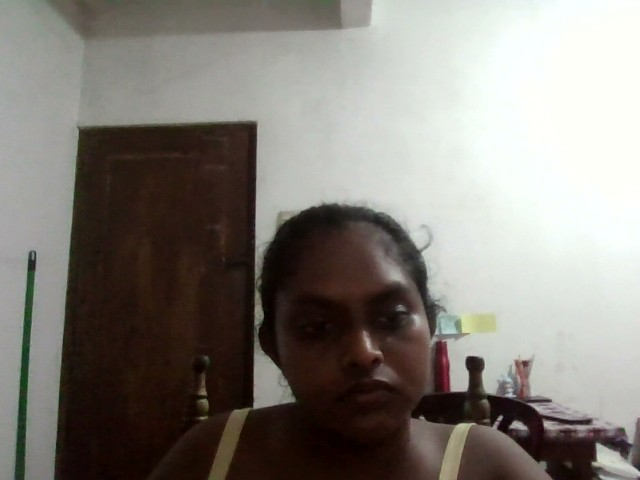

In [23]:
from google.colab import output
from IPython.display import display, Javascript
from google.colab.output import eval_js
import base64
from PIL import Image
import io

display(Javascript("""
async function captureFrame() {
  const div = document.createElement('div');

  const video = document.createElement('video');
  video.style.width = '640px';
  video.autoplay = true;

  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  video.srcObject = stream;
  div.appendChild(video);
  document.body.appendChild(div);

  await new Promise(resolve => setTimeout(resolve, 2000));

  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;

  canvas.getContext('2d').drawImage(video, 0, 0);

  stream.getTracks().forEach(track => track.stop());
  div.remove();

  return canvas.toDataURL('image/jpeg', 0.9);
}

window.captureFrame = captureFrame;
"""))

data = eval_js("captureFrame()")

image_bytes = base64.b64decode(data.split(',')[1])
image = Image.open(io.BytesIO(image_bytes))

print("Camera frame captured:", image.size)

display(image)

In [24]:
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Create detectors
base_options_face = python.BaseOptions(model_asset_path="face_landmarker.task")
face_options = vision.FaceLandmarkerOptions(
    base_options=base_options_face,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1
)
face_detector = vision.FaceLandmarker.create_from_options(face_options)

base_options_pose = python.BaseOptions(model_asset_path="pose_landmarker.task")
pose_options = vision.PoseLandmarkerOptions(
    base_options=base_options_pose,
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1
)
pose_detector = vision.PoseLandmarker.create_from_options(pose_options)

# Convert captured PIL image to MediaPipe image
rgb = np.array(image.convert("RGB"))
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb
)

# Detect
face_result = face_detector.detect(mp_image)
pose_result = pose_detector.detect(mp_image)

print("Face landmarks:", len(face_result.face_landmarks[0]) if face_result.face_landmarks else 0)
print("Pose landmarks:", len(pose_result.pose_landmarks[0]) if pose_result.pose_landmarks else 0)

Face landmarks: 478
Pose landmarks: 33


In [25]:
# ASC-Emotion compatible landmark vector
# 33 pose + first 468 face landmarks = 501 landmarks = 1503 values

pose_landmarks = pose_result.pose_landmarks[0]
face_landmarks = face_result.face_landmarks[0][:468]

# Pose: 33 × (x,y,z)
pose_xyz = np.array(
    [[lm.x, lm.y, lm.z] for lm in pose_landmarks],
    dtype=np.float32
).reshape(-1)

# Face: first 468 × (x,y,z)
face_xyz = np.array(
    [[lm.x, lm.y, lm.z] for lm in face_landmarks],
    dtype=np.float32
).reshape(-1)

features_1503 = np.concatenate([pose_xyz, face_xyz])

print("Pose values:", len(pose_xyz))
print("Face values:", len(face_xyz))
print("TOTAL:", len(features_1503))
print("Shape:", features_1503.shape)
print("NaN:", np.isnan(features_1503).sum())

Pose values: 99
Face values: 1404
TOTAL: 1503
Shape: (1503,)
NaN: 0


In [26]:
# Capture 30 consecutive camera frames
import base64
import io
import numpy as np
from PIL import Image
from google.colab.output import eval_js
from IPython.display import display, Javascript

display(Javascript("""
async function captureFrames(n=30) {
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);

  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  video.srcObject = stream;
  await video.play();

  await new Promise(r => setTimeout(r, 1000));

  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;
  const ctx = canvas.getContext('2d');

  let frames = [];

  for (let i = 0; i < n; i++) {
    ctx.drawImage(video, 0, 0, 640, 480);
    frames.push(canvas.toDataURL('image/jpeg', 0.8));
    await new Promise(r => setTimeout(r, 100));
  }

  stream.getTracks().forEach(track => track.stop());
  video.remove();

  return frames;
}
"""))

frames_b64 = eval_js("captureFrames(30)")

print("Frames captured:", len(frames_b64))

<IPython.core.display.Javascript object>

Frames captured: 30


In [27]:
# Convert the 30 camera frames into a (30, 1503) feature sequence

import base64
import io
import numpy as np
from PIL import Image
import mediapipe as mp

sequence_features = []

for i, frame_b64 in enumerate(frames_b64):

    # Decode browser image
    image_data = base64.b64decode(frame_b64.split(",")[1])
    image = Image.open(io.BytesIO(image_data)).convert("RGB")

    rgb = np.array(image)

    # MediaPipe image
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    # Detect face + pose
    face_result = face_detector.detect(mp_image)
    pose_result = pose_detector.detect(mp_image)

    # Need both landmarks
    if not face_result.face_landmarks or not pose_result.pose_landmarks:
        print(f"Frame {i+1}: landmarks missing")
        continue

    pose_landmarks = pose_result.pose_landmarks[0]
    face_landmarks = face_result.face_landmarks[0][:468]

    # 33 pose = 99 values
    pose_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in pose_landmarks],
        dtype=np.float32
    ).reshape(-1)

    # 468 face = 1404 values
    face_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in face_landmarks],
        dtype=np.float32
    ).reshape(-1)

    # 1503 total
    features = np.concatenate([pose_xyz, face_xyz])

    sequence_features.append(features)

sequence_features = np.array(sequence_features, dtype=np.float32)

print("Valid frames:", len(sequence_features))
print("Sequence shape:", sequence_features.shape)
print("Expected: (30, 1503)")

Frame 1: landmarks missing
Frame 2: landmarks missing
Frame 3: landmarks missing
Frame 4: landmarks missing
Frame 5: landmarks missing
Frame 6: landmarks missing
Frame 7: landmarks missing
Frame 8: landmarks missing
Frame 9: landmarks missing
Frame 10: landmarks missing
Frame 11: landmarks missing
Frame 12: landmarks missing
Frame 13: landmarks missing
Frame 14: landmarks missing
Frame 15: landmarks missing
Frame 16: landmarks missing
Frame 17: landmarks missing
Frame 18: landmarks missing
Frame 19: landmarks missing
Frame 22: landmarks missing
Frame 25: landmarks missing
Frame 29: landmarks missing
Frame 30: landmarks missing
Valid frames: 7
Sequence shape: (7, 1503)
Expected: (30, 1503)


In [28]:
# Capture 30 frames again, but keep only frames where
# both face and pose landmarks are detected.

valid_features = []

for frame_b64 in frames_b64:

    image_data = base64.b64decode(frame_b64.split(",")[1])
    image = Image.open(io.BytesIO(image_data)).convert("RGB")
    rgb = np.array(image)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    face_result = face_detector.detect(mp_image)
    pose_result = pose_detector.detect(mp_image)

    if not face_result.face_landmarks or not pose_result.pose_landmarks:
        continue

    pose_landmarks = pose_result.pose_landmarks[0]
    face_landmarks = face_result.face_landmarks[0][:468]

    pose_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in pose_landmarks],
        dtype=np.float32
    ).reshape(-1)

    face_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in face_landmarks],
        dtype=np.float32
    ).reshape(-1)

    features = np.concatenate([pose_xyz, face_xyz])
    valid_features.append(features)

# Use exactly 30 valid frames
if len(valid_features) >= 30:
    sequence_features = np.array(valid_features[:30], dtype=np.float32)
    print("Valid frames:", len(valid_features))
    print("Final sequence shape:", sequence_features.shape)
else:
    print("Only", len(valid_features), "valid frames detected.")
    print("Need 30 valid frames.")

Only 7 valid frames detected.
Need 30 valid frames.


In [29]:
from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript("""
async function captureFrames(n=10) {
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);

  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  video.srcObject = stream;
  await video.play();

  await new Promise(r => setTimeout(r, 1000));

  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;
  const ctx = canvas.getContext('2d');

  let frames = [];

  for (let i = 0; i < n; i++) {
    ctx.drawImage(video, 0, 0, 640, 480);
    frames.push(canvas.toDataURL('image/jpeg', 0.8));
    await new Promise(r => setTimeout(r, 100));
  }

  stream.getTracks().forEach(track => track.stop());
  video.remove();

  return frames;
}
"""))

print("Camera capture function ready.")

<IPython.core.display.Javascript object>

Camera capture function ready.


In [30]:
from IPython.display import Javascript, display
from google.colab.output import eval_js

display(Javascript("""
window.captureFrames = async function(n) {
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);

  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  video.srcObject = stream;
  await video.play();

  await new Promise(resolve => setTimeout(resolve, 1000));

  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;

  const ctx = canvas.getContext('2d');
  const frames = [];

  for (let i = 0; i < n; i++) {
    ctx.drawImage(video, 0, 0, 640, 480);
    frames.push(canvas.toDataURL('image/jpeg', 0.8));
    await new Promise(resolve => setTimeout(resolve, 100));
  }

  stream.getTracks().forEach(track => track.stop());
  video.remove();

  return frames;
};
"""))

import time
time.sleep(1)

extra_frames_b64 = eval_js("window.captureFrames(10)")

print("Extra frames captured:", len(extra_frames_b64))

<IPython.core.display.Javascript object>

Extra frames captured: 10


In [31]:
# Combine original + extra frames and extract valid 1503-feature frames

all_frames = frames_b64 + extra_frames_b64
valid_features = []

for frame_b64 in all_frames:

    image_data = base64.b64decode(frame_b64.split(",")[1])
    image = Image.open(io.BytesIO(image_data)).convert("RGB")
    rgb = np.array(image)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    face_result = face_detector.detect(mp_image)
    pose_result = pose_detector.detect(mp_image)

    if not face_result.face_landmarks or not pose_result.pose_landmarks:
        continue

    pose_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in pose_result.pose_landmarks[0]],
        dtype=np.float32
    ).reshape(-1)

    face_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in face_result.face_landmarks[0][:468]],
        dtype=np.float32
    ).reshape(-1)

    valid_features.append(
        np.concatenate([pose_xyz, face_xyz])
    )

    if len(valid_features) == 30:
        break

sequence_features = np.array(valid_features, dtype=np.float32)

print("Valid frames collected:", len(sequence_features))
print("Sequence shape:", sequence_features.shape)

Valid frames collected: 17
Sequence shape: (17, 1503)


In [32]:
import torch
import torch.nn as nn

class BehaviourGRU(nn.Module):
    def __init__(self, input_size=1503, hidden_size=128,
                 num_layers=2, num_classes=3, dropout=0.3):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        output, _ = self.gru(x)
        last_output = output[:, -1, :]
        return self.classifier(last_output)

print("BehaviourGRU class ready.")

BehaviourGRU class ready.


In [33]:
# Load the saved checkpoint correctly

checkpoint = torch.load(
    "/content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt",
    map_location=device
)

print("Checkpoint keys:", list(checkpoint.keys()))

model = BehaviourGRU(
    input_size=checkpoint.get("input_size", 1503),
    hidden_size=checkpoint.get("hidden_size", 128),
    num_layers=checkpoint.get("num_layers", 2),
    num_classes=checkpoint.get("num_classes", 3),
    dropout=0.3
).to(device)

# Load ONLY the model weights
model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Model loaded successfully.")

Checkpoint keys: ['model_state_dict', 'input_size', 'hidden_size', 'num_layers', 'num_classes', 'classes']
Model loaded successfully.


In [36]:
!pip install -q mediapipe

In [37]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe Tasks imported successfully!")

MediaPipe Tasks imported successfully!


In [38]:
# ============================================================
# CAMERA MODEL + SCALER LOADING
# ============================================================

import os
import numpy as np
import tensorflow as tf
import joblib

BASE = "/content/drive/MyDrive/Dyslexia_Research_Model"

CAMERA_MODEL_PATH = os.path.join(
    BASE,
    "best_behaviour_gru.pt"
)

print("Checking camera model path...")
print(CAMERA_MODEL_PATH)
print("Exists:", os.path.exists(CAMERA_MODEL_PATH))

Checking camera model path...
/content/drive/MyDrive/Dyslexia_Research_Model/best_behaviour_gru.pt
Exists: True


In [39]:
# ============================================================
# LOAD CAMERA GRU MODEL
# ============================================================

import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BehaviourGRU(nn.Module):
    def __init__(self, input_size=1503, hidden_size=128,
                 num_layers=2, num_classes=3, dropout=0.3):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        output, _ = self.gru(x)
        last_output = output[:, -1, :]
        return self.classifier(last_output)


camera_model = BehaviourGRU(
    input_size=1503,
    hidden_size=128,
    num_layers=2,
    num_classes=3,
    dropout=0.3
).to(DEVICE)

checkpoint = torch.load(
    CAMERA_MODEL_PATH,
    map_location=DEVICE
)

# Handle different checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    camera_model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    camera_model.load_state_dict(checkpoint["state_dict"])
else:
    camera_model.load_state_dict(checkpoint)

camera_model.eval()

CAMERA_CLASSES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}

print("=" * 65)
print("CAMERA MODEL LOADED SUCCESSFULLY")
print("=" * 65)
print("Device :", DEVICE)
print("Input  :", "30 frames × 1503 features")
print("Classes:", CAMERA_CLASSES)

CAMERA MODEL LOADED SUCCESSFULLY
Device : cuda
Input  : 30 frames × 1503 features
Classes: {0: 'Engaged', 1: 'Distracted', 2: 'Frustrated'}


In [40]:
# ============================================================
# LOAD ASC SCALER
# ============================================================

import os
import numpy as np

ASC_SCALER_MEAN = os.path.join(
    BASE,
    "visual_sequences",
    "scaler_mean.npy"
)

ASC_SCALER_SCALE = os.path.join(
    BASE,
    "visual_sequences",
    "scaler_scale.npy"
)

print("Checking ASC scaler files...")
print("Mean :", ASC_SCALER_MEAN)
print("Scale:", ASC_SCALER_SCALE)

print("\nMean exists :", os.path.exists(ASC_SCALER_MEAN))
print("Scale exists:", os.path.exists(ASC_SCALER_SCALE))

asc_mean = np.load(ASC_SCALER_MEAN)
asc_scale = np.load(ASC_SCALER_SCALE)

print("\nASC scaler loaded!")
print("Mean shape :", asc_mean.shape)
print("Scale shape:", asc_scale.shape)

Checking ASC scaler files...
Mean : /content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences/scaler_mean.npy
Scale: /content/drive/MyDrive/Dyslexia_Research_Model/visual_sequences/scaler_scale.npy

Mean exists : True
Scale exists: True

ASC scaler loaded!
Mean shape : (1503,)
Scale shape: (1503,)


In [44]:
# ============================================================
# MEDIAPIPE TASK MODELS - FIXED DOWNLOAD
# ============================================================

import os
import urllib.request

MODEL_DIR = "/content/mediapipe_models"
os.makedirs(MODEL_DIR, exist_ok=True)

FACE_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "face_landmarker.task"
)

POSE_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "pose_landmarker_full.task"
)

# Face Landmarker
FACE_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

# Pose Landmarker FULL
POSE_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/1/"
    "pose_landmarker_full.task"
)

print("=" * 65)
print("DOWNLOADING MEDIAPIPE TASK MODELS")
print("=" * 65)

# ------------------------------------------------------------
# FACE
# ------------------------------------------------------------

if not os.path.exists(FACE_MODEL_PATH):

    print("\nDownloading Face Landmarker...")

    urllib.request.urlretrieve(
        FACE_URL,
        FACE_MODEL_PATH
    )

    print("Face Landmarker downloaded.")

else:
    print("\nFace Landmarker already exists.")


# ------------------------------------------------------------
# POSE
# ------------------------------------------------------------

if not os.path.exists(POSE_MODEL_PATH):

    print("\nDownloading Pose Landmarker FULL...")

    urllib.request.urlretrieve(
        POSE_URL,
        POSE_MODEL_PATH
    )

    print("Pose Landmarker downloaded.")

else:
    print("\nPose Landmarker already exists.")


# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL VERIFICATION")
print("=" * 65)

print(
    "Face model exists:",
    os.path.exists(FACE_MODEL_PATH)
)

print(
    "Pose model exists:",
    os.path.exists(POSE_MODEL_PATH)
)

if os.path.exists(FACE_MODEL_PATH):
    print(
        "Face size:",
        round(os.path.getsize(FACE_MODEL_PATH) / (1024 * 1024), 2),
        "MB"
    )

if os.path.exists(POSE_MODEL_PATH):
    print(
        "Pose size:",
        round(os.path.getsize(POSE_MODEL_PATH) / (1024 * 1024), 2),
        "MB"
    )

print("=" * 65)

DOWNLOADING MEDIAPIPE TASK MODELS

Face Landmarker already exists.

Pose Landmarker downloaded.

MODEL VERIFICATION
Face model exists: True
Pose model exists: True
Face size: 3.58 MB
Pose size: 8.96 MB


In [45]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# ==============================
# INITIALIZE FACE LANDMARKER
# ==============================

face_base_options = python.BaseOptions(
    model_asset_path=FACE_MODEL_PATH
)

face_options = vision.FaceLandmarkerOptions(
    base_options=face_base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False
)

face_landmarker = vision.FaceLandmarker.create_from_options(
    face_options
)

# ==============================
# INITIALIZE POSE LANDMARKER
# ==============================

pose_base_options = python.BaseOptions(
    model_asset_path=POSE_MODEL_PATH
)

pose_options = vision.PoseLandmarkerOptions(
    base_options=pose_base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1
)

pose_landmarker = vision.PoseLandmarker.create_from_options(
    pose_options
)

print("=" * 60)
print("MEDIAPIPE LANDMARKERS READY")
print("=" * 60)
print("Face Landmarker :", "READY")
print("Pose Landmarker :", "READY")
print("=" * 60)

MEDIAPIPE LANDMARKERS READY
Face Landmarker : READY
Pose Landmarker : READY


<IPython.core.display.Javascript object>

WEBCAM FRAME CAPTURED
Frame shape: (480, 640, 3)
Frame dtype: uint8


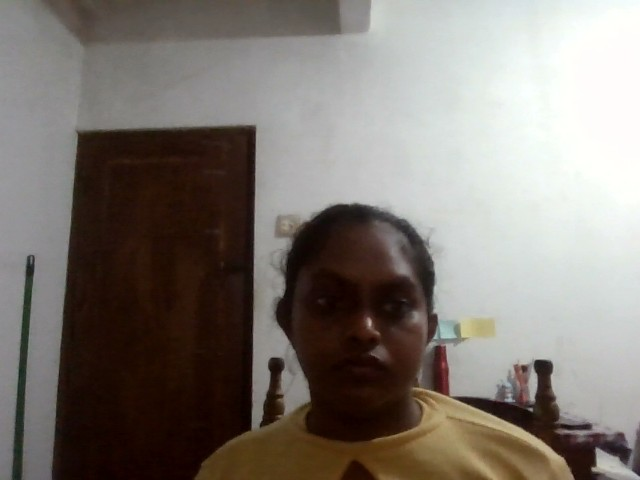

In [46]:
# ============================================================
# TEST 1 — CAPTURE ONE WEBCAM FRAME
# ============================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
import numpy as np

def capture_one_frame():
    js = Javascript(r'''
    async function captureFrame() {

        const video = document.createElement('video');
        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        document.body.appendChild(video);
        video.style.display = 'none';

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => setTimeout(resolve, 1000));

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        const ctx = canvas.getContext('2d');
        ctx.drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        video.remove();

        return canvas.toDataURL('image/jpeg', 0.9);
    }

    captureFrame();
    ''')

    display(js)

    data = eval_js("captureFrame()")
    binary = b64decode(data.split(',')[1])

    image = Image.open(io.BytesIO(binary)).convert("RGB")
    return np.array(image)


# Capture
frame_rgb = capture_one_frame()

print("=" * 60)
print("WEBCAM FRAME CAPTURED")
print("=" * 60)
print("Frame shape:", frame_rgb.shape)
print("Frame dtype:", frame_rgb.dtype)
print("=" * 60)

display(Image.fromarray(frame_rgb))

In [47]:
# ============================================================
# TEST 2 — EXTRACT FACE + POSE LANDMARKS
# ============================================================

import mediapipe as mp
import numpy as np

# Convert NumPy RGB image to MediaPipe image
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=frame_rgb
)

# ------------------------------------------------------------
# FACE LANDMARKS
# ------------------------------------------------------------
face_result = face_landmarker.detect(mp_image)

# ------------------------------------------------------------
# POSE LANDMARKS
# ------------------------------------------------------------
pose_result = pose_landmarker.detect(mp_image)

# ------------------------------------------------------------
# CHECK RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("LANDMARK EXTRACTION TEST")
print("=" * 60)

# Face
if face_result.face_landmarks:
    face_landmarks = face_result.face_landmarks[0]

    print("Face detected       : YES")
    print("Face landmarks      :", len(face_landmarks))
else:
    face_landmarks = None
    print("Face detected       : NO")

# Pose
if pose_result.pose_landmarks:
    pose_landmarks = pose_result.pose_landmarks[0]

    print("Pose detected       : YES")
    print("Pose landmarks      :", len(pose_landmarks))
else:
    pose_landmarks = None
    print("Pose detected       : NO")

print("=" * 60)

# ------------------------------------------------------------
# EXPECTED ASC STRUCTURE
# ------------------------------------------------------------

if face_landmarks is not None and pose_landmarks is not None:

    print("Expected face       : 468")
    print("Expected pose       : 33")

    print("Actual face         :", len(face_landmarks))
    print("Actual pose         :", len(pose_landmarks))

    print("=" * 60)

    if len(face_landmarks) >= 468 and len(pose_landmarks) == 33:
        print("STATUS: LANDMARK EXTRACTION READY")
    else:
        print("STATUS: LANDMARK COUNT NEEDS CHECKING")

else:
    print("STATUS: Could not detect both face and pose.")

print("=" * 60)

LANDMARK EXTRACTION TEST
Face detected       : YES
Face landmarks      : 478
Pose detected       : YES
Pose landmarks      : 33
Expected face       : 468
Expected pose       : 33
Actual face         : 478
Actual pose         : 33
STATUS: LANDMARK EXTRACTION READY


In [48]:
# ============================================================
# TEST 3 — BUILD ASC 1503-D FEATURE VECTOR
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Extract first 468 FACE landmarks
# ------------------------------------------------------------

face_xyz = np.array(
    [[lm.x, lm.y, lm.z] for lm in face_landmarks[:468]],
    dtype=np.float32
)

# Expected: (468, 3)
print("Face XYZ shape :", face_xyz.shape)


# ------------------------------------------------------------
# 2. Extract 33 POSE landmarks
# ------------------------------------------------------------

pose_xyz = np.array(
    [[lm.x, lm.y, lm.z] for lm in pose_landmarks],
    dtype=np.float32
)

# Expected: (33, 3)
print("Pose XYZ shape :", pose_xyz.shape)


# ------------------------------------------------------------
# 3. Combine
# ------------------------------------------------------------
# IMPORTANT:
# Here we use FACE(468) + POSE(33)
# = 501 landmarks
# = 1503 XYZ values

combined_landmarks = np.concatenate(
    [face_xyz, pose_xyz],
    axis=0
)

print("Combined landmarks :", combined_landmarks.shape)


# ------------------------------------------------------------
# 4. Flatten to model input
# ------------------------------------------------------------

feature_vector = combined_landmarks.flatten()

print("Feature vector shape :", feature_vector.shape)
print("Feature vector dtype :", feature_vector.dtype)


# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

print("=" * 60)

if feature_vector.shape == (1503,):
    print("STATUS: 1503-FEATURE VECTOR READY")
else:
    print("ERROR: Unexpected feature shape!")

print("=" * 60)

Face XYZ shape : (468, 3)
Pose XYZ shape : (33, 3)
Combined landmarks : (501, 3)
Feature vector shape : (1503,)
Feature vector dtype : float32
STATUS: 1503-FEATURE VECTOR READY


In [49]:
# ============================================================
# CAMERA TEST — 30 FRAME SEQUENCE → TRAINED GRU
# ============================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
import numpy as np
import torch


# ------------------------------------------------------------
# 1. COLAB WEBCAM — CAPTURE 30 FRAMES
# ------------------------------------------------------------

def capture_30_frames():

    js = Javascript(r'''
    async function captureFrames() {

        const video = document.createElement('video');

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        document.body.appendChild(video);
        video.style.display = 'none';

        video.srcObject = stream;

        await video.play();

        // Give camera time to stabilize
        await new Promise(resolve => setTimeout(resolve, 1000));

        const canvas = document.createElement('canvas');

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        const ctx = canvas.getContext('2d');

        const frames = [];

        // Capture 30 consecutive frames
        for (let i = 0; i < 30; i++) {

            ctx.drawImage(
                video,
                0,
                0,
                canvas.width,
                canvas.height
            );

            frames.push(
                canvas.toDataURL('image/jpeg', 0.85)
            );

            // ~10 FPS
            await new Promise(
                resolve => setTimeout(resolve, 100)
            );
        }

        stream.getTracks().forEach(
            track => track.stop()
        );

        video.remove();

        return frames;
    }

    captureFrames();
    ''')

    display(js)

    data = eval_js("captureFrames()")

    frames = []

    for item in data:

        binary = b64decode(
            item.split(',')[1]
        )

        image = Image.open(
            io.BytesIO(binary)
        ).convert("RGB")

        frames.append(
            np.array(image)
        )

    return frames


print("=" * 60)
print("STARTING CAMERA SEQUENCE")
print("=" * 60)

camera_frames = capture_30_frames()

print("Frames captured :", len(camera_frames))

if len(camera_frames) == 30:
    print("STATUS: 30-FRAME SEQUENCE READY")
else:
    print("ERROR: Expected 30 frames")

print("=" * 60)


# ------------------------------------------------------------
# 2. EXTRACT 1503 FEATURES FROM EACH FRAME
# ------------------------------------------------------------

sequence_features = []

for i, frame in enumerate(camera_frames):

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame
    )

    face_result = face_landmarker.detect(mp_image)
    pose_result = pose_landmarker.detect(mp_image)

    # Both must be detected
    if (
        not face_result.face_landmarks
        or not pose_result.pose_landmarks
    ):
        print(
            f"Frame {i+1}: landmark detection failed"
        )
        continue

    face = face_result.face_landmarks[0]
    pose = pose_result.pose_landmarks[0]

    # First 468 face landmarks
    face_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in face[:468]],
        dtype=np.float32
    )

    # 33 pose landmarks
    pose_xyz = np.array(
        [[lm.x, lm.y, lm.z] for lm in pose],
        dtype=np.float32
    )

    # FACE + POSE
    combined = np.concatenate(
        [face_xyz, pose_xyz],
        axis=0
    )

    feature_vector = combined.flatten()

    if feature_vector.shape == (1503,):
        sequence_features.append(
            feature_vector
        )


print("=" * 60)
print("FEATURE EXTRACTION")
print("=" * 60)

print(
    "Valid frames :",
    len(sequence_features)
)

if len(sequence_features) == 30:
    print("Feature shape:",
          np.array(sequence_features).shape)
    print("STATUS: ALL 30 FRAMES VALID")
else:
    print("STATUS: NOT ENOUGH VALID FRAMES")

print("=" * 60)


# ------------------------------------------------------------
# 3. APPLY THE SAME ASC SCALER
# ------------------------------------------------------------

if len(sequence_features) == 30:

    sequence_features = np.array(
        sequence_features,
        dtype=np.float32
    )

    # Same scaler used during model training
    scaled_sequence = (
        sequence_features - asc_mean
    ) / asc_scale

    print("Scaled sequence shape:",
          scaled_sequence.shape)


    # --------------------------------------------------------
    # 4. CREATE GRU INPUT
    # --------------------------------------------------------

    X_camera = torch.tensor(
        scaled_sequence,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    print(
        "GRU input shape:",
        tuple(X_camera.shape)
    )


    # --------------------------------------------------------
    # 5. MODEL PREDICTION
    # --------------------------------------------------------

    camera_model.eval()

    with torch.no_grad():

        logits = camera_model(
            X_camera
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]

        predicted_class = torch.argmax(
            probabilities
        ).item()


    class_names = {
        0: "Engaged",
        1: "Distracted",
        2: "Frustrated"
    }

    predicted_label = class_names[
        predicted_class
    ]


    # --------------------------------------------------------
    # 6. DISPLAY RESULT
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("CAMERA BEHAVIOUR PREDICTION")
    print("=" * 60)

    print(
        "Prediction:",
        predicted_label
    )

    print()

    for class_id, class_name in class_names.items():

        probability = (
            probabilities[class_id]
            .item() * 100
        )

        print(
            f"{class_name:12s}: "
            f"{probability:6.2f}%"
        )

    print("=" * 60)

STARTING CAMERA SEQUENCE


<IPython.core.display.Javascript object>

Frames captured : 30
STATUS: 30-FRAME SEQUENCE READY
FEATURE EXTRACTION
Valid frames : 30
Feature shape: (30, 1503)
STATUS: ALL 30 FRAMES VALID
Scaled sequence shape: (30, 1503)
GRU input shape: (1, 30, 1503)

CAMERA BEHAVIOUR PREDICTION
Prediction: Engaged

Engaged     :  46.23%
Distracted  :  43.65%
Frustrated  :  10.12%


In [51]:
# ============================================================
# VOICE MODEL — LOAD + VERIFY (FIXED)
# ============================================================

import os
import joblib
import numpy as np
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive/Behavior Detection/EmoReact_V_1.0/EmoReact_V_1.0"

AUDIO_MODEL_PATH = os.path.join(
    BASE,
    "audio_model",
    "best_audio_frustration_model.pt"
)

AUDIO_SCALER_PATH = os.path.join(
    BASE,
    "audio_model",
    "audio_scaler.pkl"
)

print("=" * 60)
print("VOICE MODEL FILE CHECK")
print("=" * 60)

print("Model exists  :", os.path.exists(AUDIO_MODEL_PATH))
print("Scaler exists :", os.path.exists(AUDIO_SCALER_PATH))

print("=" * 60)


# ------------------------------------------------------------
# 2. LOAD SCALER USING JOBLIB
# ------------------------------------------------------------

audio_scaler = joblib.load(
    AUDIO_SCALER_PATH
)

print("Audio scaler loaded : YES")
print("Scaler type         :", type(audio_scaler).__name__)


# ------------------------------------------------------------
# 3. DEFINE AUDIO MODEL
# ------------------------------------------------------------

class AudioFrustrationModel(nn.Module):

    def __init__(self, input_dim=208):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)


# ------------------------------------------------------------
# 4. LOAD TRAINED MODEL
# ------------------------------------------------------------

audio_model = AudioFrustrationModel(
    input_dim=208
)

audio_checkpoint = torch.load(
    AUDIO_MODEL_PATH,
    map_location=device
)

if (
    isinstance(audio_checkpoint, dict)
    and "model_state_dict" in audio_checkpoint
):

    audio_model.load_state_dict(
        audio_checkpoint["model_state_dict"]
    )

else:

    audio_model.load_state_dict(
        audio_checkpoint
    )

audio_model = audio_model.to(device)
audio_model.eval()


# ------------------------------------------------------------
# 5. FINAL VERIFICATION
# ------------------------------------------------------------

print("Audio model loaded  : YES")
print("Input features      : 208")
print("Output classes      : 2")

print("=" * 60)
print("VOICE MODEL READY")
print("=" * 60)

print("0 → Non-Frustrated")
print("1 → Frustrated")
print("=" * 60)

VOICE MODEL FILE CHECK
Model exists  : True
Scaler exists : True
Audio scaler loaded : YES
Scaler type         : StandardScaler
Audio model loaded  : YES
Input features      : 208
Output classes      : 2
VOICE MODEL READY
0 → Non-Frustrated
1 → Frustrated


In [53]:
# ============================================================
# MICROPHONE PERMISSION TEST
# ============================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript("""
async function testMicrophone() {
    try {
        const stream = await navigator.mediaDevices.getUserMedia({
            audio: true
        });

        stream.getTracks().forEach(track => track.stop());

        return "MICROPHONE_PERMISSION_GRANTED";
    } catch (error) {
        return "ERROR: " + error.name + " - " + error.message;
    }
}

testMicrophone();
"""))

result = eval_js("testMicrophone()")

print("=" * 60)
print("MICROPHONE PERMISSION TEST")
print("=" * 60)
print(result)
print("=" * 60)

<IPython.core.display.Javascript object>

MICROPHONE PERMISSION TEST
MICROPHONE_PERMISSION_GRANTED


In [54]:
# ============================================================
# VOICE TEST — RECORD 5 SECONDS FROM MICROPHONE
# ============================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import os

def record_audio(seconds=5):

    js = Javascript(f'''
    async function recordAudio() {{

        const stream = await navigator.mediaDevices.getUserMedia({{
            audio: true
        }});

        const recorder = new MediaRecorder(stream);
        const chunks = [];

        recorder.ondataavailable = event => {{
            chunks.push(event.data);
        }};

        recorder.start();

        await new Promise(
            resolve => setTimeout(resolve, {seconds * 1000})
        );

        recorder.stop();

        await new Promise(
            resolve => recorder.onstop = resolve
        );

        stream.getTracks().forEach(
            track => track.stop()
        );

        const blob = new Blob(
            chunks,
            {{type: 'audio/webm'}}
        );

        const buffer = await blob.arrayBuffer();

        let binary = '';
        const bytes = new Uint8Array(buffer);

        for (let i = 0; i < bytes.byteLength; i++) {{
            binary += String.fromCharCode(bytes[i]);
        }}

        return btoa(binary);
    }}

    recordAudio();
    ''')

    display(js)

    audio_base64 = eval_js("recordAudio()")

    audio_bytes = b64decode(audio_base64)

    output_path = "/content/test_voice.webm"

    with open(output_path, "wb") as f:
        f.write(audio_bytes)

    return output_path


print("=" * 60)
print("VOICE RECORDING TEST")
print("=" * 60)

audio_path = record_audio(5)

print("Recording saved :", audio_path)
print("File exists     :", os.path.exists(audio_path))

if os.path.exists(audio_path):
    print("STATUS          : RECORDING SUCCESSFUL")

print("=" * 60)

VOICE RECORDING TEST


<IPython.core.display.Javascript object>

Recording saved : /content/test_voice.webm
File exists     : True
STATUS          : RECORDING SUCCESSFUL


In [55]:
# ============================================================
# VOICE TEST — EXTRACT 208 AUDIO FEATURES
# ============================================================

import os
import subprocess
import numpy as np
import librosa

WEBM_PATH = "/content/test_voice.webm"
WAV_PATH = "/content/test_voice_16k.wav"

# ------------------------------------------------------------
# 1. CONVERT WEBM → 16 kHz MONO WAV
# ------------------------------------------------------------

print("=" * 60)
print("AUDIO CONVERSION")
print("=" * 60)

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", WEBM_PATH,
    "-ar", "16000",
    "-ac", "1",
    WAV_PATH
], stdout=subprocess.PIPE, stderr=subprocess.PIPE)

print("WAV exists :", os.path.exists(WAV_PATH))


# ------------------------------------------------------------
# 2. LOAD AUDIO
# ------------------------------------------------------------

audio, sr = librosa.load(
    WAV_PATH,
    sr=16000,
    mono=True
)

print("Sample rate :", sr)
print("Duration    :", round(len(audio) / sr, 2), "seconds")
print("Samples     :", len(audio))


# ------------------------------------------------------------
# 3. MFCC FEATURES
# ------------------------------------------------------------

mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=40
)

mfcc_mean = np.mean(
    mfcc,
    axis=1
)

mfcc_std = np.std(
    mfcc,
    axis=1
)


# ------------------------------------------------------------
# 4. LOG-MEL FEATURES
# ------------------------------------------------------------

mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=64
)

log_mel = librosa.power_to_db(
    mel,
    ref=np.max
)

logmel_mean = np.mean(
    log_mel,
    axis=1
)

logmel_std = np.std(
    log_mel,
    axis=1
)


# ------------------------------------------------------------
# 5. COMBINE → 208 FEATURES
# ------------------------------------------------------------

audio_features = np.concatenate([
    mfcc_mean,       # 40
    mfcc_std,        # 40
    logmel_mean,     # 64
    logmel_std       # 64
])

audio_features = audio_features.astype(
    np.float32
)


# ------------------------------------------------------------
# 6. VERIFY
# ------------------------------------------------------------

print("=" * 60)
print("AUDIO FEATURE EXTRACTION")
print("=" * 60)

print("MFCC shape       :", mfcc.shape)
print("Log-Mel shape    :", log_mel.shape)

print("MFCC mean        :", mfcc_mean.shape)
print("MFCC std         :", mfcc_std.shape)
print("Log-Mel mean     :", logmel_mean.shape)
print("Log-Mel std      :", logmel_std.shape)

print("-" * 60)

print("FINAL FEATURES   :", audio_features.shape)
print("Feature count    :", len(audio_features))

if len(audio_features) == 208:
    print("STATUS: 208 FEATURES READY")
else:
    print("ERROR: FEATURE COUNT IS NOT 208")

print("=" * 60)

AUDIO CONVERSION
WAV exists : True
Sample rate : 16000
Duration    : 4.98 seconds
Samples     : 79680
AUDIO FEATURE EXTRACTION
MFCC shape       : (40, 156)
Log-Mel shape    : (64, 156)
MFCC mean        : (40,)
MFCC std         : (40,)
Log-Mel mean     : (64,)
Log-Mel std      : (64,)
------------------------------------------------------------
FINAL FEATURES   : (208,)
Feature count    : 208
STATUS: 208 FEATURES READY


In [56]:
# ============================================================
# VOICE TEST — FRUSTRATION PREDICTION
# ============================================================

# ------------------------------------------------------------
# 1. APPLY THE SAME SCALER USED DURING TRAINING
# ------------------------------------------------------------

scaled_audio = audio_scaler.transform(
    audio_features.reshape(1, -1)
)

print("=" * 60)
print("AUDIO MODEL PREDICTION")
print("=" * 60)

print("Original shape :", audio_features.shape)
print("Scaled shape   :", scaled_audio.shape)


# ------------------------------------------------------------
# 2. CONVERT TO PYTORCH TENSOR
# ------------------------------------------------------------

X_audio = torch.tensor(
    scaled_audio,
    dtype=torch.float32
).to(device)

print("Model input    :", tuple(X_audio.shape))


# ------------------------------------------------------------
# 3. PREDICT
# ------------------------------------------------------------

audio_model.eval()

with torch.no_grad():

    audio_logits = audio_model(
        X_audio
    )

    audio_probabilities = torch.softmax(
        audio_logits,
        dim=1
    )[0]


# ------------------------------------------------------------
# 4. GET PROBABILITIES
# ------------------------------------------------------------

non_frustrated_prob = (
    audio_probabilities[0].item() * 100
)

frustrated_prob = (
    audio_probabilities[1].item() * 100
)


# ------------------------------------------------------------
# 5. FINAL RESULT
# ------------------------------------------------------------

if frustrated_prob >= non_frustrated_prob:
    audio_prediction = "Frustrated"
else:
    audio_prediction = "Non-Frustrated"


print()
print("=" * 60)
print("VOICE BEHAVIOUR RESULT")
print("=" * 60)

print(
    f"Non-Frustrated : {non_frustrated_prob:.2f}%"
)

print(
    f"Frustrated     : {frustrated_prob:.2f}%"
)

print("-" * 60)

print(
    "Prediction     :",
    audio_prediction
)

print("=" * 60)

AUDIO MODEL PREDICTION
Original shape : (208,)
Scaled shape   : (1, 208)
Model input    : (1, 208)

VOICE BEHAVIOUR RESULT
Non-Frustrated : 99.84%
Frustrated     : 0.16%
------------------------------------------------------------
Prediction     : Non-Frustrated


In [57]:
# ============================================================
# INTERACTION MODEL — FILE CHECK
# ============================================================

import os

INTERACTION_DIR = "/content/drive/MyDrive/Dyslexia_Research_Model/pinsoRo_behavior"

print("=" * 60)
print("INTERACTION MODEL FILE CHECK")
print("=" * 60)

print("Directory exists :", os.path.exists(INTERACTION_DIR))

if os.path.exists(INTERACTION_DIR):

    files = os.listdir(INTERACTION_DIR)

    for f in files:
        print(" -", f)

print("=" * 60)

INTERACTION MODEL FILE CHECK
Directory exists : True
 - pinsoRo_train_v3.csv
 - pinsoRo_val_v3.csv
 - pinsoRo_test_v3.csv
 - best_interaction_model.keras


In [58]:
# ============================================================
# INTERACTION MODEL — LOAD + VERIFY
# ============================================================

import tensorflow as tf
import numpy as np

INTERACTION_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "pinsoRo_behavior/"
    "best_interaction_model.keras"
)

print("=" * 60)
print("LOADING INTERACTION MODEL")
print("=" * 60)

print(
    "Model exists :",
    os.path.exists(INTERACTION_MODEL_PATH)
)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

interaction_model = tf.keras.models.load_model(
    INTERACTION_MODEL_PATH
)

print("Model loaded : YES")

# ------------------------------------------------------------
# MODEL INFORMATION
# ------------------------------------------------------------

print()
print("Model input shape  :", interaction_model.input_shape)
print("Model output shape :", interaction_model.output_shape)

print()
print("Model summary:")
interaction_model.summary()

print("=" * 60)
print("INTERACTION MODEL READY")
print("=" * 60)

LOADING INTERACTION MODEL
Model exists : True
Model loaded : YES

Model input shape  : (None, 6)
Model output shape : (None, 3)

Model summary:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,883 (30.80 KB)

 Trainable params: 2,627 (10.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,256 (20.54 KB)

INTERACTION MODEL READY


In [59]:
# ============================================================
# INTERACTION MODEL — REAL TEST SAMPLE PREDICTION
# ============================================================

import pandas as pd
import numpy as np

INTERACTION_DIR = (
    "/content/drive/MyDrive/"
    "Dyslexia_Research_Model/"
    "pinsoRo_behavior"
)

TEST_CSV = os.path.join(
    INTERACTION_DIR,
    "pinsoRo_test_v3.csv"
)

# ------------------------------------------------------------
# 1. LOAD TEST DATA
# ------------------------------------------------------------

interaction_test = pd.read_csv(TEST_CSV)

print("=" * 60)
print("INTERACTION TEST DATA")
print("=" * 60)

print("Test shape :", interaction_test.shape)

print()
print("Columns:")
print(list(interaction_test.columns))

print("=" * 60)


# ------------------------------------------------------------
# 2. REQUIRED 6 FEATURES
# ------------------------------------------------------------

interaction_features = [
    "pose_movement_mean",
    "pose_movement_std",
    "face_movement_mean",
    "face_movement_std",
    "hand_movement_mean",
    "hand_movement_std"
]

missing = [
    col for col in interaction_features
    if col not in interaction_test.columns
]

if missing:
    print("ERROR — Missing features:", missing)

else:

    print("All 6 features found : YES")

    # --------------------------------------------------------
    # 3. TAKE ONE REAL TEST SAMPLE
    # --------------------------------------------------------

    sample = interaction_test[
        interaction_features
    ].iloc[[0]].astype(np.float32)

    print()
    print("Sample features:")
    print(sample)

    print()
    print("Input shape :", sample.shape)


    # --------------------------------------------------------
    # 4. PREDICT
    # --------------------------------------------------------

    interaction_probabilities = (
        interaction_model.predict(
            sample,
            verbose=0
        )[0]
    )

    predicted_class = int(
        np.argmax(
            interaction_probabilities
        )
    )

    class_names = {
        0: "Engaged",
        1: "Distracted",
        2: "Frustrated"
    }

    predicted_label = class_names[
        predicted_class
    ]


    # --------------------------------------------------------
    # 5. DISPLAY RESULT
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("INTERACTION MODEL PREDICTION")
    print("=" * 60)

    print(
        "Prediction :",
        predicted_label
    )

    print()

    for class_id, class_name in class_names.items():

        probability = (
            interaction_probabilities[class_id]
            * 100
        )

        print(
            f"{class_name:12s}: "
            f"{probability:6.2f}%"
        )

    print("=" * 60)

INTERACTION TEST DATA
Test shape : (909, 13)

Columns:
['session_id', 'stream', 'window_id', 'window_start', 'window_end', 'n_frames', 'pose_movement_mean', 'pose_movement_std', 'face_movement_mean', 'face_movement_std', 'hand_movement_mean', 'hand_movement_std', 'behavior_state']
All 6 features found : YES

Sample features:
   pose_movement_mean  pose_movement_std  face_movement_mean  \
0            0.014153           0.009873            0.039969   

   face_movement_std  hand_movement_mean  hand_movement_std  
0           0.020134            0.053782           0.028696  

Input shape : (1, 6)

INTERACTION MODEL PREDICTION
Prediction : Frustrated

Engaged     :  18.80%
Distracted  :  15.49%
Frustrated  :  65.70%


In [60]:
# ============================================================
# MULTIMODAL BEHAVIOUR FUSION
# Camera + Voice + Interaction
# ============================================================

import numpy as np

# ------------------------------------------------------------
# CLASS ORDER
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}


# ------------------------------------------------------------
# GET CAMERA PROBABILITIES
# ------------------------------------------------------------

camera_probs = (
    probabilities.detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)

# Expected:
# [Engaged, Distracted, Frustrated]


# ------------------------------------------------------------
# GET INTERACTION PROBABILITIES
# ------------------------------------------------------------

interaction_probs = (
    interaction_probabilities
    .astype(np.float32)
)

# Expected:
# [Engaged, Distracted, Frustrated]


# ------------------------------------------------------------
# GET VOICE FRUSTRATION PROBABILITY
# ------------------------------------------------------------

voice_frustrated = (
    frustrated_prob / 100.0
)

# Convert binary voice output into
# 3-class evidence vector.
#
# Voice model only detects frustration.
#
# [Non-Frustrated, No direct Distracted evidence,
#  Frustrated]

voice_probs = np.array([
    1.0 - voice_frustrated,
    0.0,
    voice_frustrated
], dtype=np.float32)


# ------------------------------------------------------------
# FUSION WEIGHTS
# ------------------------------------------------------------

CAMERA_WEIGHT = 0.55
INTERACTION_WEIGHT = 0.30
VOICE_WEIGHT = 0.15


# ------------------------------------------------------------
# WEIGHTED FUSION
# ------------------------------------------------------------

fused_probs = (
    CAMERA_WEIGHT * camera_probs
    +
    INTERACTION_WEIGHT * interaction_probs
    +
    VOICE_WEIGHT * voice_probs
)


# Normalize
fused_probs = (
    fused_probs / fused_probs.sum()
)


# ------------------------------------------------------------
# FINAL PREDICTION
# ------------------------------------------------------------

final_class = int(
    np.argmax(fused_probs)
)

final_prediction = CLASS_NAMES[
    final_class
]


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 60)
print("MULTIMODAL BEHAVIOUR FUSION")
print("=" * 60)

print()
print("CAMERA")
print("-" * 60)

for i, name in CLASS_NAMES.items():
    print(
        f"{name:12s}: "
        f"{camera_probs[i] * 100:6.2f}%"
    )


print()
print("VOICE")
print("-" * 60)

print(
    f"Frustrated evidence : "
    f"{voice_frustrated * 100:6.2f}%"
)


print()
print("INTERACTION")
print("-" * 60)

for i, name in CLASS_NAMES.items():
    print(
        f"{name:12s}: "
        f"{interaction_probs[i] * 100:6.2f}%"
    )


print()
print("=" * 60)
print("FINAL FUSED BEHAVIOUR")
print("=" * 60)

for i, name in CLASS_NAMES.items():
    print(
        f"{name:12s}: "
        f"{fused_probs[i] * 100:6.2f}%"
    )

print("-" * 60)

print(
    "FINAL PREDICTION :",
    final_prediction
)

print("=" * 60)

MULTIMODAL BEHAVIOUR FUSION

CAMERA
------------------------------------------------------------
Engaged     :  46.23%
Distracted  :  43.65%
Frustrated  :  10.12%

VOICE
------------------------------------------------------------
Frustrated evidence :   0.16%

INTERACTION
------------------------------------------------------------
Engaged     :  18.80%
Distracted  :  15.49%
Frustrated  :  65.70%

FINAL FUSED BEHAVIOUR
Engaged     :  46.04%
Distracted  :  28.66%
Frustrated  :  25.30%
------------------------------------------------------------
FINAL PREDICTION : Engaged


In [61]:
# ============================================================
# ADAPTIVE MULTIMODAL BEHAVIOUR FUSION
# Handles missing modalities
# ============================================================

import numpy as np


# ------------------------------------------------------------
# CLASS DEFINITIONS
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}


# ------------------------------------------------------------
# ADAPTIVE FUSION FUNCTION
# ------------------------------------------------------------

def adaptive_fusion(
    camera_probs=None,
    interaction_probs=None,
    voice_frustrated=None
):
    """
    Adaptive multimodal behaviour prediction.

    Available modalities can be:
        Camera
        Interaction
        Voice

    Returns:
        Final behaviour
        Confidence
        Fused probabilities
    """

    modality_probs = []
    modality_weights = []


    # ========================================================
    # CAMERA
    # ========================================================

    if camera_probs is not None:

        camera_probs = np.asarray(
            camera_probs,
            dtype=np.float32
        )

        if camera_probs.shape == (3,):

            modality_probs.append(
                camera_probs
            )

            modality_weights.append(
                0.55
            )


    # ========================================================
    # INTERACTION
    # ========================================================

    if interaction_probs is not None:

        interaction_probs = np.asarray(
            interaction_probs,
            dtype=np.float32
        )

        if interaction_probs.shape == (3,):

            modality_probs.append(
                interaction_probs
            )

            modality_weights.append(
                0.30
            )


    # ========================================================
    # VOICE
    # ========================================================

    if voice_frustrated is not None:

        voice_frustrated = float(
            voice_frustrated
        )

        voice_frustrated = np.clip(
            voice_frustrated,
            0.0,
            1.0
        )

        # Voice model only provides frustration
        # evidence.
        #
        # It does NOT directly predict Distracted.

        voice_probs = np.array([
            1.0 - voice_frustrated,
            0.0,
            voice_frustrated
        ], dtype=np.float32)

        modality_probs.append(
            voice_probs
        )

        modality_weights.append(
            0.15
        )


    # ========================================================
    # NO MODALITY AVAILABLE
    # ========================================================

    if len(modality_probs) == 0:

        return {
            "prediction": "No Prediction",
            "confidence": 0.0,
            "probabilities": None,
            "modalities_used": []
        }


    # ========================================================
    # NORMALIZE WEIGHTS
    # ========================================================

    modality_weights = np.asarray(
        modality_weights,
        dtype=np.float32
    )

    modality_weights = (
        modality_weights /
        modality_weights.sum()
    )


    # ========================================================
    # WEIGHTED FUSION
    # ========================================================

    fused = np.zeros(
        3,
        dtype=np.float32
    )

    for probs, weight in zip(
        modality_probs,
        modality_weights
    ):

        fused += (
            weight * probs
        )


    # Final normalization
    fused = (
        fused /
        fused.sum()
    )


    # ========================================================
    # FINAL CLASS
    # ========================================================

    final_class = int(
        np.argmax(fused)
    )

    final_prediction = CLASS_NAMES[
        final_class
    ]

    confidence = float(
        fused[final_class]
    )


    # ========================================================
    # RETURN RESULT
    # ========================================================

    return {
        "prediction": final_prediction,
        "confidence": confidence,
        "probabilities": fused,
        "modalities_used": len(modality_probs)
    }


# ============================================================
# TEST — ALL THREE MODALITIES
# ============================================================

result = adaptive_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)


print("=" * 60)
print("ADAPTIVE MULTIMODAL FUSION")
print("=" * 60)

print(
    "Modalities used :",
    result["modalities_used"]
)

print()

for i, name in CLASS_NAMES.items():

    print(
        f"{name:12s}: "
        f"{result['probabilities'][i] * 100:6.2f}%"
    )

print("-" * 60)

print(
    "Prediction :",
    result["prediction"]
)

print(
    "Confidence :",
    f"{result['confidence'] * 100:.2f}%"
)

print("=" * 60)

ADAPTIVE MULTIMODAL FUSION
Modalities used : 3

Engaged     :  46.04%
Distracted  :  28.66%
Frustrated  :  25.30%
------------------------------------------------------------
Prediction : Engaged
Confidence : 46.04%


In [62]:
# ============================================================
# ADAPTIVE FUSION — ALL MODALITY COMBINATIONS
# ============================================================

test_cases = {

    "Camera + Voice + Interaction": {
        "camera_probs": camera_probs,
        "interaction_probs": interaction_probs,
        "voice_frustrated": voice_frustrated
    },

    "Camera + Interaction": {
        "camera_probs": camera_probs,
        "interaction_probs": interaction_probs,
        "voice_frustrated": None
    },

    "Voice + Interaction": {
        "camera_probs": None,
        "interaction_probs": interaction_probs,
        "voice_frustrated": voice_frustrated
    },

    "Interaction Only": {
        "camera_probs": None,
        "interaction_probs": interaction_probs,
        "voice_frustrated": None
    },

    "Camera Only": {
        "camera_probs": camera_probs,
        "interaction_probs": None,
        "voice_frustrated": None
    },

    "Voice Only": {
        "camera_probs": None,
        "interaction_probs": None,
        "voice_frustrated": voice_frustrated
    },

    "No Modality": {
        "camera_probs": None,
        "interaction_probs": None,
        "voice_frustrated": None
    }
}


print("=" * 70)
print("MODALITY ADAPTABILITY VALIDATION")
print("=" * 70)


for case_name, inputs in test_cases.items():

    result = adaptive_fusion(**inputs)

    print()
    print("-" * 70)
    print(case_name)

    print(
        "Prediction :",
        result["prediction"]
    )

    print(
        "Confidence :",
        f"{result['confidence'] * 100:.2f}%"
    )

    print(
        "Modalities :",
        result["modalities_used"]
    )

    if result["probabilities"] is not None:

        print(
            f"Engaged     : "
            f"{result['probabilities'][0] * 100:.2f}%"
        )

        print(
            f"Distracted  : "
            f"{result['probabilities'][1] * 100:.2f}%"
        )

        print(
            f"Frustrated  : "
            f"{result['probabilities'][2] * 100:.2f}%"
        )

print()
print("=" * 70)
print("VALIDATION COMPLETE")
print("=" * 70)

MODALITY ADAPTABILITY VALIDATION

----------------------------------------------------------------------
Camera + Voice + Interaction
Prediction : Engaged
Confidence : 46.04%
Modalities : 3
Engaged     : 46.04%
Distracted  : 28.66%
Frustrated  : 25.30%

----------------------------------------------------------------------
Camera + Interaction
Prediction : Engaged
Confidence : 36.55%
Modalities : 2
Engaged     : 36.55%
Distracted  : 33.71%
Frustrated  : 29.74%

----------------------------------------------------------------------
Voice + Interaction
Prediction : Engaged
Confidence : 45.82%
Modalities : 2
Engaged     : 45.82%
Distracted  : 10.33%
Frustrated  : 43.86%

----------------------------------------------------------------------
Interaction Only
Prediction : Frustrated
Confidence : 65.70%
Modalities : 1
Engaged     : 18.80%
Distracted  : 15.49%
Frustrated  : 65.70%

----------------------------------------------------------------------
Camera Only
Prediction : Engaged
Confiden

In [63]:
# ============================================================
# RESEARCH-CORRECT ADAPTIVE MULTIMODAL FUSION
# ============================================================

import numpy as np


CLASS_NAMES = {
    0: "Engaged",
    1: "Distracted",
    2: "Frustrated"
}


def research_correct_fusion(
    camera_probs=None,
    interaction_probs=None,
    voice_frustrated=None
):
    """
    Research-correct multimodal fusion.

    Camera:
        Engaged / Distracted / Frustrated

    Interaction:
        Engaged / Distracted / Frustrated

    Voice:
        Non-Frustrated / Frustrated
        -> frustration evidence only
    """

    # --------------------------------------------------------
    # CHECK AVAILABLE MODALITIES
    # --------------------------------------------------------

    camera_available = camera_probs is not None
    interaction_available = interaction_probs is not None
    voice_available = voice_frustrated is not None


    # --------------------------------------------------------
    # NO MODALITY
    # --------------------------------------------------------

    if not (
        camera_available
        or interaction_available
        or voice_available
    ):

        return {
            "prediction": "No Prediction",
            "confidence": 0.0,
            "probabilities": None,
            "voice_state": None,
            "modalities_used": []
        }


    # --------------------------------------------------------
    # VOICE ONLY
    # --------------------------------------------------------

    if (
        voice_available
        and not camera_available
        and not interaction_available
    ):

        vf = float(
            np.clip(
                voice_frustrated,
                0.0,
                1.0
            )
        )

        if vf >= 0.5:
            prediction = "Frustrated"
            confidence = vf
            voice_state = "Frustrated"

        else:
            prediction = "Non-Frustrated"
            confidence = 1.0 - vf
            voice_state = "Non-Frustrated"

        return {
            "prediction": prediction,
            "confidence": confidence,
            "probabilities": None,
            "voice_state": voice_state,
            "modalities_used": ["Voice"]
        }


    # --------------------------------------------------------
    # START 3-CLASS BASE FUSION
    # --------------------------------------------------------

    fused = np.zeros(
        3,
        dtype=np.float32
    )

    total_weight = 0.0

    modalities_used = []


    # --------------------------------------------------------
    # CAMERA
    # --------------------------------------------------------

    if camera_available:

        cp = np.asarray(
            camera_probs,
            dtype=np.float32
        )

        if cp.shape != (3,):
            raise ValueError(
                "Camera probabilities must have shape (3,)"
            )

        fused += 0.55 * cp
        total_weight += 0.55

        modalities_used.append("Camera")


    # --------------------------------------------------------
    # INTERACTION
    # --------------------------------------------------------

    if interaction_available:

        ip = np.asarray(
            interaction_probs,
            dtype=np.float32
        )

        if ip.shape != (3,):
            raise ValueError(
                "Interaction probabilities must have shape (3,)"
            )

        fused += 0.30 * ip
        total_weight += 0.30

        modalities_used.append("Interaction")


    # --------------------------------------------------------
    # VOICE — FRUSTRATION EVIDENCE ONLY
    # --------------------------------------------------------

    voice_state = None

    if voice_available:

        vf = float(
            np.clip(
                voice_frustrated,
                0.0,
                1.0
            )
        )

        # Voice does NOT create Engaged or Distracted.
        #
        # It contributes only to Frustrated evidence.
        #
        # Use voice confidence as frustration evidence.

        voice_vector = np.array([
            0.0,
            0.0,
            vf
        ], dtype=np.float32)

        fused += 0.15 * voice_vector
        total_weight += 0.15

        voice_state = (
            "Frustrated"
            if vf >= 0.5
            else "Non-Frustrated"
        )

        modalities_used.append("Voice")


    # --------------------------------------------------------
    # NORMALIZE AVAILABLE MODALITY WEIGHTS
    # --------------------------------------------------------

    fused = fused / total_weight


    # --------------------------------------------------------
    # NORMALIZE FINAL PROBABILITIES
    # --------------------------------------------------------

    probability_sum = fused.sum()

    if probability_sum > 0:

        fused = fused / probability_sum

    else:

        return {
            "prediction": "No Prediction",
            "confidence": 0.0,
            "probabilities": None,
            "voice_state": voice_state,
            "modalities_used": modalities_used
        }


    # --------------------------------------------------------
    # FINAL 3-CLASS PREDICTION
    # --------------------------------------------------------

    final_class = int(
        np.argmax(fused)
    )

    final_prediction = CLASS_NAMES[
        final_class
    ]

    confidence = float(
        fused[final_class]
    )


    return {
        "prediction": final_prediction,
        "confidence": confidence,
        "probabilities": fused,
        "voice_state": voice_state,
        "modalities_used": modalities_used
    }


# ============================================================
# TEST ALL THREE MODALITIES
# ============================================================

result = research_correct_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)


print("=" * 70)
print("RESEARCH-CORRECT MULTIMODAL FUSION")
print("=" * 70)

print(
    "Modalities used :",
    result["modalities_used"]
)

print()

if result["probabilities"] is not None:

    for i, name in CLASS_NAMES.items():

        print(
            f"{name:12s}: "
            f"{result['probabilities'][i] * 100:6.2f}%"
        )

print("-" * 70)

print(
    "Voice state     :",
    result["voice_state"]
)

print(
    "Final prediction:",
    result["prediction"]
)

print(
    "Confidence      :",
    f"{result['confidence'] * 100:.2f}%"
)

print("=" * 70)

RESEARCH-CORRECT MULTIMODAL FUSION
Modalities used : ['Camera', 'Interaction', 'Voice']

Engaged     :  36.54%
Distracted  :  33.70%
Frustrated  :  29.75%
----------------------------------------------------------------------
Voice state     : Non-Frustrated
Final prediction: Engaged
Confidence      : 36.54%


In [64]:
# ============================================================
# FINAL MODALITY COMBINATION VALIDATION
# ============================================================

final_test_cases = {

    "Camera + Voice + Interaction": {
        "camera_probs": camera_probs,
        "interaction_probs": interaction_probs,
        "voice_frustrated": voice_frustrated
    },

    "Camera + Interaction": {
        "camera_probs": camera_probs,
        "interaction_probs": interaction_probs,
        "voice_frustrated": None
    },

    "Voice + Interaction": {
        "camera_probs": None,
        "interaction_probs": interaction_probs,
        "voice_frustrated": voice_frustrated
    },

    "Interaction Only": {
        "camera_probs": None,
        "interaction_probs": interaction_probs,
        "voice_frustrated": None
    },

    "Camera Only": {
        "camera_probs": camera_probs,
        "interaction_probs": None,
        "voice_frustrated": None
    },

    "Voice Only": {
        "camera_probs": None,
        "interaction_probs": None,
        "voice_frustrated": voice_frustrated
    },

    "No Modality": {
        "camera_probs": None,
        "interaction_probs": None,
        "voice_frustrated": None
    }
}


print("=" * 75)
print("FINAL MODALITY ADAPTABILITY VALIDATION")
print("=" * 75)


for case_name, inputs in final_test_cases.items():

    result = research_correct_fusion(**inputs)

    print()
    print("-" * 75)
    print(case_name)
    print("-" * 75)

    print(
        "Modalities used :",
        result["modalities_used"]
    )

    print(
        "Prediction      :",
        result["prediction"]
    )

    print(
        "Confidence      :",
        f"{result['confidence'] * 100:.2f}%"
    )

    if result["voice_state"] is not None:
        print(
            "Voice state     :",
            result["voice_state"]
        )

    if result["probabilities"] is not None:

        print(
            f"Engaged         : "
            f"{result['probabilities'][0] * 100:.2f}%"
        )

        print(
            f"Distracted      : "
            f"{result['probabilities'][1] * 100:.2f}%"
        )

        print(
            f"Frustrated      : "
            f"{result['probabilities'][2] * 100:.2f}%"
        )


print()
print("=" * 75)
print("FINAL VALIDATION COMPLETE")
print("=" * 75)

FINAL MODALITY ADAPTABILITY VALIDATION

---------------------------------------------------------------------------
Camera + Voice + Interaction
---------------------------------------------------------------------------
Modalities used : ['Camera', 'Interaction', 'Voice']
Prediction      : Engaged
Confidence      : 36.54%
Voice state     : Non-Frustrated
Engaged         : 36.54%
Distracted      : 33.70%
Frustrated      : 29.75%

---------------------------------------------------------------------------
Camera + Interaction
---------------------------------------------------------------------------
Modalities used : ['Camera', 'Interaction']
Prediction      : Engaged
Confidence      : 36.55%
Engaged         : 36.55%
Distracted      : 33.71%
Frustrated      : 29.74%

---------------------------------------------------------------------------
Voice + Interaction
---------------------------------------------------------------------------
Modalities used : ['Interaction', 'Voice']
Predict

In [66]:
# ============================================================
# FINAL BEHAVIOUR DECISION SYSTEM — FIXED
# ============================================================

from collections import deque

CONFIDENCE_THRESHOLD = 0.50
SMOOTHING_WINDOW = 3

behavior_history = deque(
    maxlen=SMOOTHING_WINDOW
)


def stable_behaviour_decision(fused_result):

    prediction = fused_result["prediction"]
    confidence = fused_result["confidence"]

    # --------------------------------------------------------
    # NO PREDICTION
    # --------------------------------------------------------

    if prediction == "No Prediction":

        return {
            "state": "No Prediction",
            "confidence": 0.0,
            "stable": False
        }

    # --------------------------------------------------------
    # CONFIDENCE CHECK
    # --------------------------------------------------------

    if confidence < CONFIDENCE_THRESHOLD:

        return {
            "state": "Uncertain",
            "confidence": confidence,
            "stable": False
        }

    # --------------------------------------------------------
    # ADD PREDICTION TO HISTORY
    # --------------------------------------------------------

    behavior_history.append(prediction)

    # --------------------------------------------------------
    # MAJORITY VOTE
    # --------------------------------------------------------

    counts = {}

    for state in behavior_history:
        counts[state] = counts.get(state, 0) + 1

    stable_state = max(
        counts,
        key=counts.get
    )

    stable_count = counts[stable_state]

    required_votes = (
        len(behavior_history) // 2 + 1
    )

    is_stable = (
        stable_count >= required_votes
    )

    return {
        "state": stable_state if is_stable else "Uncertain",
        "confidence": confidence,
        "stable": is_stable
    }


# ============================================================
# IMPORTANT:
# USE THE CURRENT 3-MODALITY FUSION RESULT
# ============================================================

current_fusion_result = research_correct_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)


# ------------------------------------------------------------
# TEST 3 CONSECUTIVE PREDICTIONS
# ------------------------------------------------------------

print("=" * 70)
print("FINAL BEHAVIOUR DECISION SYSTEM")
print("=" * 70)

for i in range(3):

    decision = stable_behaviour_decision(
        current_fusion_result
    )

    print(
        f"Step {i+1}: "
        f"{decision['state']} | "
        f"{decision['confidence'] * 100:.2f}% | "
        f"Stable = {decision['stable']}"
    )

print("=" * 70)

FINAL BEHAVIOUR DECISION SYSTEM
Step 1: Uncertain | 36.54% | Stable = False
Step 2: Uncertain | 36.54% | Stable = False
Step 3: Uncertain | 36.54% | Stable = False


In [67]:
# ============================================================
# TEMPORAL STABILITY TEST
# ============================================================

behavior_history.clear()

test_predictions = [
    {"prediction": "Engaged", "confidence": 0.62},
    {"prediction": "Engaged", "confidence": 0.68},
    {"prediction": "Engaged", "confidence": 0.71},
]

print("=" * 70)
print("TEMPORAL STABILITY TEST")
print("=" * 70)

for i, fusion_result in enumerate(test_predictions, start=1):

    decision = stable_behaviour_decision(fusion_result)

    print(
        f"Step {i}: "
        f"Prediction = {fusion_result['prediction']} | "
        f"Confidence = {fusion_result['confidence']*100:.2f}% | "
        f"Final State = {decision['state']} | "
        f"Stable = {decision['stable']}"
    )

TEMPORAL STABILITY TEST
Step 1: Prediction = Engaged | Confidence = 62.00% | Final State = Engaged | Stable = True
Step 2: Prediction = Engaged | Confidence = 68.00% | Final State = Engaged | Stable = True
Step 3: Prediction = Engaged | Confidence = 71.00% | Final State = Engaged | Stable = True


In [68]:
# ============================================================
# FINAL PIPELINE — ACTUAL CURRENT MODEL OUTPUTS
# ============================================================

behavior_history.clear()

fusion_result = research_correct_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)

final_decision = stable_behaviour_decision(
    fusion_result
)

print("=" * 70)
print("FINAL BEHAVIOUR DECISION")
print("=" * 70)

print(f"Modalities Used : {fusion_result['modalities_used']}")
print(f"Fusion Prediction: {fusion_result['prediction']}")
print(f"Fusion Confidence: {fusion_result['confidence']*100:.2f}%")

if fusion_result["probabilities"] is not None:
    print("\nFusion Probabilities:")
    for idx, name in CLASS_NAMES.items():
        print(
            f"  {name}: "
            f"{fusion_result['probabilities'][idx]*100:.2f}%"
        )

print(f"\nVoice State      : {fusion_result['voice_state']}")
print(f"Final State      : {final_decision['state']}")
print(f"Final Confidence : {final_decision['confidence']*100:.2f}%")
print(f"Stable           : {final_decision['stable']}")

print("=" * 70)

FINAL BEHAVIOUR DECISION
Modalities Used : ['Camera', 'Interaction', 'Voice']
Fusion Prediction: Engaged
Fusion Confidence: 36.54%

Fusion Probabilities:
  Engaged: 36.54%
  Distracted: 33.70%
  Frustrated: 29.75%

Voice State      : Non-Frustrated
Final State      : Uncertain
Final Confidence : 36.54%
Stable           : False


In [69]:
# ============================================================
# TEMPORAL BEHAVIOUR SEQUENCE TEST
# ============================================================

behavior_history.clear()

sequence = [
    {"prediction": "Engaged",    "confidence": 0.62},
    {"prediction": "Engaged",    "confidence": 0.68},
    {"prediction": "Distracted", "confidence": 0.64},
    {"prediction": "Distracted", "confidence": 0.72},
    {"prediction": "Distracted", "confidence": 0.78},
    {"prediction": "Frustrated", "confidence": 0.81},
    {"prediction": "Frustrated", "confidence": 0.85},
    {"prediction": "Frustrated", "confidence": 0.88},
]

print("=" * 70)
print("TEMPORAL BEHAVIOUR SEQUENCE TEST")
print("=" * 70)

for i, fusion_result in enumerate(sequence, start=1):

    decision = stable_behaviour_decision(fusion_result)

    print(
        f"Step {i:02d} | "
        f"Model: {fusion_result['prediction']:10s} | "
        f"Conf: {fusion_result['confidence']*100:5.1f}% | "
        f"Final: {decision['state']:10s} | "
        f"Stable: {decision['stable']}"
    )

TEMPORAL BEHAVIOUR SEQUENCE TEST
Step 01 | Model: Engaged    | Conf:  62.0% | Final: Engaged    | Stable: True
Step 02 | Model: Engaged    | Conf:  68.0% | Final: Engaged    | Stable: True
Step 03 | Model: Distracted | Conf:  64.0% | Final: Engaged    | Stable: True
Step 04 | Model: Distracted | Conf:  72.0% | Final: Distracted | Stable: True
Step 05 | Model: Distracted | Conf:  78.0% | Final: Distracted | Stable: True
Step 06 | Model: Frustrated | Conf:  81.0% | Final: Distracted | Stable: True
Step 07 | Model: Frustrated | Conf:  85.0% | Final: Frustrated | Stable: True
Step 08 | Model: Frustrated | Conf:  88.0% | Final: Frustrated | Stable: True


In [70]:
# ============================================================
# REAL MODEL TEMPORAL TEST
# ============================================================

import numpy as np

behavior_history.clear()

print("=" * 70)
print("REAL MODEL TEMPORAL BEHAVIOUR TEST")
print("=" * 70)

# Current model outputs
# These are the actual probabilities already generated
# by Camera + Interaction + Voice.

real_fusion_result = research_correct_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)

print("\nActual Fusion Result:")
print(f"Prediction : {real_fusion_result['prediction']}")
print(f"Confidence : {real_fusion_result['confidence']*100:.2f}%")
print(f"Modalities : {real_fusion_result['modalities_used']}")

if real_fusion_result["probabilities"] is not None:
    print("\nProbabilities:")
    for idx, name in CLASS_NAMES.items():
        print(
            f"  {name}: "
            f"{real_fusion_result['probabilities'][idx]*100:.2f}%"
        )

# ------------------------------------------------------------
# Apply final decision layer
# ------------------------------------------------------------

final_decision = stable_behaviour_decision(
    real_fusion_result
)

print("\nFinal Decision:")
print(f"State      : {final_decision['state']}")
print(f"Confidence : {final_decision['confidence']*100:.2f}%")
print(f"Stable     : {final_decision['stable']}")

print("=" * 70)

REAL MODEL TEMPORAL BEHAVIOUR TEST

Actual Fusion Result:
Prediction : Engaged
Confidence : 36.54%
Modalities : ['Camera', 'Interaction', 'Voice']

Probabilities:
  Engaged: 36.54%
  Distracted: 33.70%
  Frustrated: 29.75%

Final Decision:
State      : Uncertain
Confidence : 36.54%
Stable     : False


In [71]:
# ============================================================
# REAL CAMERA 30-FRAME TEST
# ============================================================

import cv2
import numpy as np
import mediapipe as mp
from google.colab.output import eval_js
from IPython.display import Javascript, display
import base64
from PIL import Image
from io import BytesIO

print("=" * 70)
print("REAL CAMERA 30-FRAME TEST")
print("=" * 70)

# ------------------------------------------------------------
# Capture 30 frames from browser camera
# ------------------------------------------------------------

display(Javascript("""
async function captureFrames() {

    const video = document.createElement('video');
    video.style.width = '640px';
    video.style.height = '480px';

    const stream = await navigator.mediaDevices.getUserMedia({
        video: true
    });

    video.srcObject = stream;
    await video.play();

    document.body.appendChild(video);

    const canvas = document.createElement('canvas');
    canvas.width = 640;
    canvas.height = 480;

    let frames = [];

    for (let i = 0; i < 30; i++) {

        await new Promise(resolve =>
            setTimeout(resolve, 100)
        );

        const ctx = canvas.getContext('2d');
        ctx.drawImage(video, 0, 0, 640, 480);

        frames.push(
            canvas.toDataURL('image/jpeg')
        );
    }

    stream.getTracks().forEach(track => track.stop());
    video.remove();

    return frames;
}
"""))

frames_b64 = eval_js("captureFrames()")

print(f"Captured frames: {len(frames_b64)}")

REAL CAMERA 30-FRAME TEST


<IPython.core.display.Javascript object>

Captured frames: 30


In [72]:
# ============================================================
# 30 FRAMES → MEDIAPIPE → 1503 FEATURES → GRU
# ============================================================

import cv2
import numpy as np
import base64
from PIL import Image
from io import BytesIO

# ------------------------------------------------------------
# Convert captured base64 frames to RGB images
# ------------------------------------------------------------

rgb_frames = []

for frame_b64 in frames_b64:
    encoded = frame_b64.split(",", 1)[1]
    img_bytes = base64.b64decode(encoded)

    img = Image.open(
        BytesIO(img_bytes)
    ).convert("RGB")

    rgb_frames.append(
        np.array(img)
    )

print("RGB frames:", len(rgb_frames))
print("Frame shape:", rgb_frames[0].shape)


# ------------------------------------------------------------
# MediaPipe Tasks
# ------------------------------------------------------------

BaseOptions = mp.tasks.BaseOptions
VisionRunningMode = mp.tasks.vision.RunningMode

FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions

PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions


face_options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="/content/face_landmarker.task"
    ),
    running_mode=VisionRunningMode.IMAGE
)

pose_options = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="/content/pose_landmarker.task"
    ),
    running_mode=VisionRunningMode.IMAGE
)

face_detector = FaceLandmarker.create_from_options(
    face_options
)

pose_detector = PoseLandmarker.create_from_options(
    pose_options
)


# ------------------------------------------------------------
# Extract 501 landmarks = 1503 values
# ------------------------------------------------------------

sequence = []

valid_frames = 0

for frame in rgb_frames:

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame
    )

    face_result = face_detector.detect(mp_image)
    pose_result = pose_detector.detect(mp_image)

    # Need both face and pose
    if (
        not face_result.face_landmarks
        or not pose_result.pose_landmarks
    ):
        continue

    face = face_result.face_landmarks[0]
    pose = pose_result.pose_landmarks[0]

    # 468 face landmarks
    face_xyz = np.array(
        [[p.x, p.y, p.z] for p in face[:468]],
        dtype=np.float32
    )

    # 33 pose landmarks
    pose_xyz = np.array(
        [[p.x, p.y, p.z] for p in pose],
        dtype=np.float32
    )

    if face_xyz.shape != (468, 3):
        continue

    if pose_xyz.shape != (33, 3):
        continue

    # ASC-style 501 landmarks
    landmarks = np.concatenate(
        [face_xyz, pose_xyz],
        axis=0
    )

    features = landmarks.reshape(-1)

    if features.shape[0] != 1503:
        continue

    sequence.append(features)
    valid_frames += 1


print("\nValid frames:", valid_frames)
print("Feature shape per frame:",
      sequence[0].shape if sequence else None)

RGB frames: 30
Frame shape: (480, 640, 3)

Valid frames: 30
Feature shape per frame: (1503,)


In [74]:
# ============================================================
# FIX DEVICE MISMATCH + REAL CAMERA PREDICTION
# ============================================================

device = next(camera_model.parameters()).device
print("Model device:", device)

camera_input = camera_input.to(device)

camera_model.eval()

with torch.no_grad():
    logits = camera_model(camera_input)
    camera_probs_tensor = torch.softmax(logits, dim=1)

camera_probs = camera_probs_tensor.cpu().numpy()[0]

camera_prediction_idx = np.argmax(camera_probs)
camera_prediction = CLASS_NAMES[camera_prediction_idx]

print("\n" + "=" * 70)
print("REAL CAMERA BEHAVIOUR PREDICTION")
print("=" * 70)

for idx, name in CLASS_NAMES.items():
    print(f"{name:10s}: {camera_probs[idx] * 100:.2f}%")

print("-" * 70)
print("Prediction :", camera_prediction)
print(
    "Confidence :",
    f"{camera_probs[camera_prediction_idx] * 100:.2f}%"
)
print("=" * 70)

Model device: cuda:0

REAL CAMERA BEHAVIOUR PREDICTION
Engaged   : 17.66%
Distracted: 53.29%
Frustrated: 29.05%
----------------------------------------------------------------------
Prediction : Distracted
Confidence : 53.29%


In [75]:
# ============================================================
# REAL CAMERA → TEMPORAL STABILITY TEST
# ============================================================

# Use the current real-camera prediction as one temporal decision
real_camera_result = {
    "prediction": camera_prediction,
    "confidence": float(camera_probs[camera_prediction_idx])
}

# Reset history for a fresh test
behavior_history.clear()

stable_result = stable_behaviour_decision(real_camera_result)

print("=" * 70)
print("REAL CAMERA TEMPORAL DECISION")
print("=" * 70)

print("Raw Prediction :", real_camera_result["prediction"])
print(
    "Confidence     :",
    f"{real_camera_result['confidence'] * 100:.2f}%"
)
print("Stable State   :", stable_result["state"])
print(
    "Stable         :",
    stable_result["stable"]
)
print(
    "Decision Conf. :",
    f"{stable_result['confidence'] * 100:.2f}%"
)

print("=" * 70)

REAL CAMERA TEMPORAL DECISION
Raw Prediction : Distracted
Confidence     : 53.29%
Stable State   : Distracted
Stable         : True
Decision Conf. : 53.29%


In [76]:
# ============================================================
# REAL CAMERA + VOICE + INTERACTION
# RESEARCH-CORRECT FUSION
# ============================================================

real_fusion_result = research_correct_fusion(
    camera_probs=camera_probs,
    interaction_probs=interaction_probs,
    voice_frustrated=voice_frustrated
)

print("=" * 70)
print("REAL MULTIMODAL BEHAVIOUR FUSION")
print("=" * 70)

print("Modalities Used :", real_fusion_result["modalities_used"])
print("Prediction      :", real_fusion_result["prediction"])
print(
    "Confidence      :",
    f"{real_fusion_result['confidence'] * 100:.2f}%"
)

print("\nFused Probabilities:")

if real_fusion_result["probabilities"] is not None:
    for idx, name in CLASS_NAMES.items():
        print(
            f"{name:10s}: "
            f"{real_fusion_result['probabilities'][idx] * 100:.2f}%"
        )

print("\nVoice State     :", real_fusion_result["voice_state"])

print("=" * 70)

REAL MULTIMODAL BEHAVIOUR FUSION
Modalities Used : ['Camera', 'Interaction', 'Voice']
Prediction      : Frustrated
Confidence      : 42.00%

Fused Probabilities:
Engaged   : 18.06%
Distracted: 39.94%
Frustrated: 42.00%

Voice State     : Non-Frustrated


In [77]:
# ============================================================
# REAL MULTIMODAL FUSION → TEMPORAL DECISION
# ============================================================

behavior_history.clear()

stable_fusion_result = stable_behaviour_decision(
    real_fusion_result
)

print("=" * 70)
print("REAL MULTIMODAL TEMPORAL DECISION")
print("=" * 70)

print("Fusion Prediction :", real_fusion_result["prediction"])
print(
    "Fusion Confidence :",
    f"{real_fusion_result['confidence'] * 100:.2f}%"
)

print("-" * 70)

print("Final State       :", stable_fusion_result["state"])
print(
    "Final Confidence  :",
    f"{stable_fusion_result['confidence'] * 100:.2f}%"
)
print("Stable            :", stable_fusion_result["stable"])

print("=" * 70)

REAL MULTIMODAL TEMPORAL DECISION
Fusion Prediction : Frustrated
Fusion Confidence : 42.00%
----------------------------------------------------------------------
Final State       : Uncertain
Final Confidence  : 42.00%
Stable            : False


In [78]:
# ============================================================
# FINAL MODALITY AVAILABILITY VALIDATION
# ============================================================

test_cases = {
    "Camera + Voice + Interaction": {
        "camera": camera_probs,
        "interaction": interaction_probs,
        "voice": voice_frustrated
    },
    "Camera + Interaction": {
        "camera": camera_probs,
        "interaction": interaction_probs,
        "voice": None
    },
    "Voice + Interaction": {
        "camera": None,
        "interaction": interaction_probs,
        "voice": voice_frustrated
    },
    "Interaction Only": {
        "camera": None,
        "interaction": interaction_probs,
        "voice": None
    },
    "Camera Only": {
        "camera": camera_probs,
        "interaction": None,
        "voice": None
    },
    "Voice Only": {
        "camera": None,
        "interaction": None,
        "voice": voice_frustrated
    },
    "No Modality": {
        "camera": None,
        "interaction": None,
        "voice": None
    }
}

print("=" * 80)
print("FINAL MODALITY AVAILABILITY VALIDATION")
print("=" * 80)

for case_name, inputs in test_cases.items():

    result = research_correct_fusion(
        camera_probs=inputs["camera"],
        interaction_probs=inputs["interaction"],
        voice_frustrated=inputs["voice"]
    )

    print(f"\n[{case_name}]")
    print("Modalities :", result["modalities_used"])
    print("Prediction :", result["prediction"])
    print(
        "Confidence :",
        f"{result['confidence'] * 100:.2f}%"
    )
    print("Voice State:", result["voice_state"])

print("\n" + "=" * 80)

FINAL MODALITY AVAILABILITY VALIDATION

[Camera + Voice + Interaction]
Modalities : ['Camera', 'Interaction', 'Voice']
Prediction : Frustrated
Confidence : 42.00%
Voice State: Non-Frustrated

[Camera + Interaction]
Modalities : ['Camera', 'Interaction']
Prediction : Frustrated
Confidence : 41.99%
Voice State: None

[Voice + Interaction]
Modalities : ['Interaction', 'Voice']
Prediction : Frustrated
Confidence : 65.73%
Voice State: Non-Frustrated

[Interaction Only]
Modalities : ['Interaction']
Prediction : Frustrated
Confidence : 65.70%
Voice State: None

[Camera Only]
Modalities : ['Camera']
Prediction : Distracted
Confidence : 53.29%
Voice State: None

[Voice Only]
Modalities : ['Voice']
Prediction : Non-Frustrated
Confidence : 99.84%
Voice State: Non-Frustrated

[No Modality]
Modalities : []
Prediction : No Prediction
Confidence : 0.00%
Voice State: None

